# RPDA8412 — ICE Task 2: Data Analysis Progress Notebook (v2.1)
## Assessing the Impact of Generative AI on South African Digital Artists

**Student:** Aphiwe Langalethu Mbonambi (ST10083669) · **Supervisor:** Mr Donald Dandawa · **Notebook:** `RPDA8412_ICE2_analysis_v2.1.ipynb` · **Date:** 15 October 2026

This notebook re-runs the ICE 2 analysis on the **final fieldwork data**: 21 survey submissions and 11 interviews
(v1.1 had 13 submissions and 3 interviews). The design is unchanged: explanatory sequential, QUAN → qual + doc, with the
screening, sample-size, coding and sentiment rules fixed in advance in ICE Task 1 (Mbonambi, 2026). What changed is the
data, and the data forced several decisions. They are listed first, using the lecture framework for managing
methodological change (IIE, 2026), and each one is implemented and logged in code below.

| What changed | Why | What was done instead | Impact on the findings |
|---|---|---|---|
| The survey closed at **21 submissions, 14 eligible** | Fieldwork time ran out; no further responses expected | ICE 1 contingency for *n* < 50 at close: multivariable modelling **abandoned**, SQ2 reported as association, not prediction | No factor ranking. SQ2 rests on descriptive and bivariate results plus the interviews |
| **Scope expanded** from digital illustrators, concept artists and animators to **digital creative professionals** (design, social media and content, architecture and visualisation, platform work). The form was revised (first v2 submission 19 Oct): screen *digital creative work, past 3 years*, new occupation and employment options, five new items | The original population could not supply enough responses in the time available. Researcher's decision; the supervisor (Mr Dandawa) was informed | Each row carries a `form_version` flag; option sets are harmonised; the **original-scope subgroup** (the ICE 1 population) is reported beside the **expanded-scope** respondents in every survey table | 8 of the 14 eligible respondents come from the expanded scope. The two groups differ, so results are shown for both rather than averaged |
| **11 interviews** (ICE 1 planned 6–8): 10 practitioners and 1 stakeholder | Scope expansion; interviewees recruited through available networks, largely one organisation and its partner | Each interview gets a **scope tier**: original (P2), expanded (7), peripheral (2: creative work incidental to the role), stakeholder (P10). Every count is shown by tier | One interview speaks from the original population; claims are labelled by tier |
| **Inputs corrected by the researcher (5 Nov):** interview dates and times added; values entered into three v2-only items for v1 respondents removed | Issues found in v2.0 | The integrity check in 1.2 is kept as a guard and now passes. The contact-details column (Q7.2) is still in the export and is dropped before analysis | No identifiable data in the notebook; v2-only items are analysed for v2 respondents only |
| Codebook **v0.2 → v0.3** (21 → 29 codes) | New mechanisms in the new interviews (insourcing, junior roles, signalling human work, workplace AI rules) | Eight inductive codes added; every first-pass assignment reviewed and logged | Three new candidate themes; the four v1 themes re-tested on all 11 interviews |

| Strand | Input | Status at this checkpoint |
|---|---|---|
| Survey (QUAN, dominant) | `survey_responses_v2_deid.xlsx`: Google Forms export, 21 submissions (15 Sep – 29 Oct 2026), contact column removed | Final. Cleaned, harmonised, screened, described; bivariate tests run; modelling abandoned by the ICE 1 rule |
| Interviews (qual) | `P1`–`P11_transcript_deid.txt`: de-identified transcripts (12 Oct – 3 Nov 2026) | Final. Speaker attribution, scope tiers, guide coverage, first-cycle coding (codebook v0.3), candidate themes |
| Documents (doc) | Document register | **Not started** in this notebook |

**Running in Google Colab:** run the setup cell, then upload the 12 input files when prompted (or place them in
`data/`). Outputs are written to `outputs/figures` and `outputs/tables`. Only de-identified files are used. The original
recordings, transcripts, the survey export with contact details and the name-to-pseudonym key stay on the institutional
OneDrive and are never loaded here (ICE 1 §3.7; POPIA).

In [1]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  SETUP — run first (and after every runtime restart)                  ║
# ╚══════════════════════════════════════════════════════════════════════╝
import sys, subprocess, re, shutil, warnings
from pathlib import Path

try:
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
except ImportError:                      # Colab does not ship VADER's standalone package
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "vaderSentiment"], check=True)
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 120)

NOTEBOOK_VERSION = "v2.1 — 5 Nov 2026 (final fieldwork data, corrected inputs: 21 survey submissions, 11 interviews)"
V = "v2"                                 # suffix for every exported table
SEED = 2026
rng = np.random.default_rng(SEED)

DATA, OUT = Path("data"), Path("outputs")
FIG, TAB = OUT / "figures", OUT / "tables"
for p in (DATA, FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)

PIDS = [f"P{i}" for i in range(1, 12)]
INPUTS = ["survey_responses_v2_deid.xlsx"] + [f"{p}_transcript_deid.txt" for p in PIDS]
# If the files were uploaded somewhere else (e.g. the Colab Files panel at /content or /), copy them into data/
for f in INPUTS:
    if not (DATA / f).exists():
        for d in (Path("."), Path("/content"), Path("/content/drive/MyDrive"), Path("/")):
            if (d / f).exists():
                shutil.copy(d / f, DATA / f)
                print(f"found {f} in {d.resolve()}/ → copied to {DATA}/")
                break
if "google.colab" in sys.modules and not all((DATA / f).exists() for f in INPUTS):
    from google.colab import files
    print("Upload the input files:", ", ".join(INPUTS))
    for name, content in files.upload().items():
        (DATA / name).write_bytes(content)
missing = [f for f in INPUTS if not (DATA / f).exists()]
assert not missing, f"Missing input files in {DATA}/: {missing}"

# One quiet house style for every figure
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
C_CORE, C_ELIG, C_ALL, C_INT = "#104281", "#2a78d6", "#eb6834", "#1baf7a"
LIKERT_COLORS = {1: "#d64545", 2: "#f0a3a1", 3: "#d9d8d2", 4: "#86b6ef", 5: "#2a78d6"}
LIKERT_NAMES = {1: "Strongly disagree", 2: "Disagree", 3: "Neutral", 4: "Agree", 5: "Strongly agree"}
mpl.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 9, "text.color": INK,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlesize": 10.5,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK2, "ytick.color": INK2, "figure.dpi": 110,
    "savefig.dpi": 220, "savefig.bbox": "tight", "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", facecolor="white")
    print(f"saved → {FIG / (name + '.png')}")

def pct(k, n):
    return f"{k}/{n} ({100 * k / n:.0f}%)" if n else "—"

def wilson(k, n, z=1.96):
    """Wilson score 95% interval for a proportion: stays inside [0, 1] and behaves at small n."""
    if n == 0:
        return np.nan, np.nan
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return max(0, c - h), min(1, c + h)

print("Setup complete —", NOTEBOOK_VERSION)

found survey_responses_v2_deid.xlsx in // → copied to data/
found P1_transcript_deid.txt in // → copied to data/
found P2_transcript_deid.txt in // → copied to data/
found P3_transcript_deid.txt in // → copied to data/
found P4_transcript_deid.txt in // → copied to data/
found P5_transcript_deid.txt in // → copied to data/
found P6_transcript_deid.txt in // → copied to data/
found P7_transcript_deid.txt in // → copied to data/
found P8_transcript_deid.txt in // → copied to data/
found P9_transcript_deid.txt in // → copied to data/
found P10_transcript_deid.txt in // → copied to data/
found P11_transcript_deid.txt in // → copied to data/
Setup complete — v2.1 — 5 Nov 2026 (final fieldwork data, corrected inputs: 21 survey submissions, 11 interviews)


## 1. Load the survey export and apply the data dictionary

Each Google Forms column gets a short analysis code, so every variable can be traced to its exact question wording.
Respondents get a sequential, non-identifying ID (`R01`–`R21`, in submission order). A guard drops any contact-details
column before anything else runs, so the notebook stays safe even if the raw export is loaded by mistake. A
`form_version` flag records which version of the questionnaire each person answered: the v2-only question Q1.11 is
present for every v2 submission and absent for every v1 submission.

In [2]:
raw = pd.read_excel(DATA / "survey_responses_v2_deid.xlsx")
PII = [c for c in raw.columns if re.search(r"name and (e-?mail|email)|cellphone|phone number", c, re.I)]
if PII:                                   # never display or keep contact details (ICE 1 §3.7)
    raw = raw.drop(columns=PII)
    print(f"Contact-details column(s) removed on load: {len(PII)}")
print(f"Survey export: {raw.shape[0]} submissions × {raw.shape[1]} columns (no contact details)")

#            code                     section            type                    role in the analysis
DICTIONARY = [
    ("timestamp",               "Meta",              "datetime",             "Submission time"),
    ("scr_adult",               "Screening",         "Yes/No",               "Eligibility (18+)"),
    ("scr_sa",                  "Screening",         "Yes/No",               "Eligibility (lives and works in SA)"),
    ("scr_prof",                "Screening",         "Yes/No",               "Eligibility (professional practice; wording differs by version)"),
    ("scr_aiaware",             "Screening",         "Yes/No",               "Awareness of generative AI in the field"),
    ("age_band",                "1 Demographics",    "ordinal",              "Descriptive"),
    ("gender",                  "1 Demographics",    "nominal",              "Descriptive"),
    ("province",                "1 Demographics",    "nominal",              "Descriptive / segmentation"),
    ("subfield_raw",            "1 Demographics",    "nominal (+other)",     "Scope tier; segmentation; model covariate"),
    ("years_exp",               "1 Demographics",    "ordinal",              "Descriptive; consistency check"),
    ("employment",              "1 Demographics",    "nominal",              "Segmentation; model covariate"),
    ("career_stage",            "1 Demographics",    "ordinal",              "H2 predictor"),
    ("training",                "1 Demographics",    "ordinal",              "Descriptive"),
    ("income_share",            "1 Demographics",    "ordinal",              "Descriptive (dependence on creative income)"),
    ("ai_aware_len",            "2 AI adoption",     "ordinal",              "Descriptive"),
    ("ai_use_freq",             "2 AI adoption",     "Likert 1–5",           "H1 predictor (own use)"),
    ("ai_purposes",             "2 AI adoption",     "multi-select",         "Descriptive"),
    ("peer_adoption",           "2 AI adoption",     "Likert 1–5",           "H1 predictor (adoption in field)"),
    ("ai_tools",                "2 AI adoption",     "multi-select",         "Descriptive"),
    ("client_req_ai",           "2 AI adoption",     "Yes/No/Maybe/Not sure", "Descriptive"),
    ("client_req_cleanup",      "2 AI adoption",     "Yes/No/Not sure",      "Descriptive"),
    ("income_change",           "3 Income",          "ordinal",              "SQ1 outcome descriptor"),
    ("loss_freq",               "3 Income",          "Likert 1–5",           "Secondary outcome (Tier-2 ordinal model)"),
    ("comm_lost",               "3 Income",          "ordinal count band",   "SQ1 outcome descriptor"),
    ("ai_loss",                 "3 Income",          "Yes/No",               "PRIMARY OUTCOME (H1–H3)"),
    ("lowered_rates",           "3 Income",          "Yes/No (+N/A in v2)",  "SQ1 outcome descriptor"),
    ("changed_offering",        "3 Income",          "Yes/No",               "SQ1 outcome descriptor"),
    ("job_security",            "3 Income",          "Likert 1–5",           "SQ1 outcome descriptor"),
    ("leg_aware",               "4 Legal",           "Likert 1–5",           "H3a predictor; legal-knowledge scale"),
    ("leg_understand",          "4 Legal",           "Likert 1–5",           "Legal-knowledge scale; H3b"),
    ("leg_adequate",            "4 Legal",           "Likert 1–5",           "Belief in adequacy of current law"),
    ("leg_support_new",         "4 Legal",           "Likert 1–5",           "Demand for protection"),
    ("leg_know_steps",          "4 Legal",           "Likert 1–5",           "Legal-knowledge scale; H3b"),
    ("leg_industry_bodies",     "4 Legal",           "Likert 1–5",           "Demand for protection"),
    ("id_threat",               "5 Identity",        "Likert (text or 1–5)", "Identity-threat scale"),
    ("id_skill_value",          "5 Identity",        "Likert (text or 1–5)", "Identity-threat scale"),
    ("id_motivation",           "5 Identity",        "Likert (text or 1–5)", "Identity-threat scale"),
    ("id_pride_changed",        "5 Identity",        "Likert (text or 1–5)", "Identity-threat scale"),
    ("id_client_value_human",   "5 Identity",        "Likert (text or 1–5)", "Perceived market value of human work"),
    ("id_optimism",             "5 Identity",        "Likert (text or 1–5)", "Career optimism"),
    ("id_tool_not_replace",     "5 Identity",        "Likert (text or 1–5)", "Tool vs replacement framing"),
    ("txt_work_income",         "6 Open-ended",      "free text",            "SQ3 text corpus"),
    ("txt_identity",            "6 Open-ended",      "free text",            "SQ3 text corpus"),
    ("txt_protections",         "6 Open-ended",      "free text",            "SQ3 text corpus"),
    ("txt_other",               "6 Open-ended",      "free text",            "SQ3 text corpus"),
    ("interview_optin",         "7 Follow-up",       "Yes/No/Maybe",         "Interview sampling frame"),
    ("other_areas",             "1 Demographics",    "multi-select (v2)",    "Descriptive (v2 only)"),
    ("income_source",           "1 Demographics",    "nominal (v2)",         "Descriptive (v2 only); version flag"),
    ("employer_policy",         "2 AI adoption",     "Yes/No/Not sure (v2)", "Descriptive (v2 only)"),
    ("role_change",             "3 Income",          "multi-select (v2)",    "Descriptive (v2 only)"),
    ("leg_disclosure",          "4 Legal",           "Likert 1–5 (v2)",      "Descriptive (v2 only)"),
]
assert len(DICTIONARY) == raw.shape[1], "Column count changed — update the data dictionary"

df = raw.copy()
df.columns = [d[0] for d in DICTIONARY]
df.insert(0, "resp_id", [f"R{i:02d}" for i in range(1, len(df) + 1)])
df.insert(1, "form_version", np.where(df.income_source.notna(), "v2", "v1"))
assert df.loc[df.form_version == "v1", "timestamp"].max() < df.loc[df.form_version == "v2", "timestamp"].min(), \
    "version flag is not consistent with submission order"

data_dictionary = pd.DataFrame(DICTIONARY, columns=["code", "section", "type", "role"])
data_dictionary.insert(1, "question", [c.strip() for c in raw.columns])
data_dictionary.to_csv(TAB / f"data_dictionary_{V}.csv", index=False)
display(data_dictionary[["code", "section", "type", "role"]].iloc[[0, 3, 8, 11, 15, 24, 28, 34, 47, 49]])
print(df.groupby("form_version").timestamp.agg(["count", "min", "max"]).rename(columns={"count": "submissions"}))

Survey export: 21 submissions × 51 columns (no contact details)


,code,section,type,role
0,timestamp,Meta,datetime,Submission time
3,scr_prof,Screening,Yes/No,Eligibility (professional practice; wording differs by version)
8,subfield_raw,1 Demographics,nominal (+other),Scope tier; segmentation; model covariate
11,career_stage,1 Demographics,ordinal,H2 predictor
15,ai_use_freq,2 AI adoption,Likert 1–5,H1 predictor (own use)
24,ai_loss,3 Income,Yes/No,PRIMARY OUTCOME (H1–H3)
28,leg_aware,4 Legal,Likert 1–5,H3a predictor; legal-knowledge scale
34,id_threat,5 Identity,Likert (text or 1–5),Identity-threat scale
47,income_source,1 Demographics,nominal (v2),Descriptive (v2 only); version flag
49,role_change,3 Income,multi-select (v2),Descriptive (v2 only)


              submissions                     min                     max
form_version                                                             
v1                     13 2026-09-15 14:08:14.280 2026-10-12 08:58:37.919
v2                      8 2026-10-19 14:32:44.759 2026-10-29 12:44:30.531


### 1.1 Two versions of the questionnaire: harmonisation log

R01–R13 answered the original form (v1); R14–R21 answered the revised form (v2). The table records every difference
that affects the analysis and the rule used to put both versions on one scale. Nothing is recoded silently.

In [3]:
HARMONISATION = pd.DataFrame([
    ["Screening Q3 (professional practice)", "digital artist/animator, past 5 years", "digital creative work, past 3 years",
     "Eligibility taken as answered; the version flag records which wording applied"],
    ["Q1.4 main occupation", "illustration, concept art, animation sub-fields + write-ins",
     "adds design, social media & content, independent & platform-based, architecture",
     "Grouped into 7 sub-field groups and 3 scope tiers (original = ICE 1 population; expanded; outside)"],
    ["Q1.7 employment type", "3 options", "5 options (in-house, studio/agency, own business, government, mixed)",
     "Harmonised to Employed / Independent or own business / Mixed"],
    ["Q2.3 purposes, Q2.5 tools", "short option list", "longer list; several options contain commas",
     "Matched against known option strings, not split on commas; v2-only options missing for v1 rows"],
    ["Q2.4 peer adoption", "1–5 numbers", "top point labelled '5 - Very widely'", "Leading digit"],
    ["Q3.5 lowered rates", "Yes / No", "adds 'Not applicable (I am salaried)' and 'Considering it'",
     "Not applicable → missing; Considering it → No"],
    ["Q5.1–Q5.7 identity items", "text labels", "text labels or 1–5 numbers", "Both mapped to 1–5"],
    ["Q1.5, Q1.11, Q2.8, Q3.8, Q4.7", "not asked", "new items", "Analysed for v2 respondents only (section 5.4)"],
], columns=["Item", "v1 (R01–R13)", "v2 (R14–R21)", "Harmonisation rule"])
HARMONISATION.to_csv(TAB / f"instrument_harmonisation_{V}.csv", index=False)
display(HARMONISATION)

,Item,v1 (R01–R13),v2 (R14–R21),Harmonisation rule
0,Screening Q3 (professional practice),"digital artist/animator, past 5 years","digital creative work, past 3 years",Eligibility taken as answered; the version flag records which wording applied
1,Q1.4 main occupation,"illustration, concept art, animation sub-fields + write-ins","adds design, social media & content, independent & platform-based, architecture",Grouped into 7 sub-field groups and 3 scope tiers (original = ICE 1 population; expanded; outside)
2,Q1.7 employment type,3 options,"5 options (in-house, studio/agency, own business, government, mixed)",Harmonised to Employed / Independent or own business / Mixed
3,"Q2.3 purposes, Q2.5 tools",short option list,longer list; several options contain commas,"Matched against known option strings, not split on commas; v2-only options missing for v1 rows"
4,Q2.4 peer adoption,1–5 numbers,top point labelled '5 - Very widely',Leading digit
5,Q3.5 lowered rates,Yes / No,adds 'Not applicable (I am salaried)' and 'Considering it',Not applicable → missing; Considering it → No
6,Q5.1–Q5.7 identity items,text labels,text labels or 1–5 numbers,Both mapped to 1–5
7,"Q1.5, Q1.11, Q2.8, Q3.8, Q4.7",not asked,new items,Analysed for v2 respondents only (section 5.4)


### 1.2 Data-integrity check: values in questions a respondent never saw

Google Forms leaves earlier responses blank when a question is added to a live form, so the five v2-only items must be
empty for R01–R13. In the v2.0 run three of them were not: values had been entered for v1 respondents who never saw the
questions. The researcher removed those entries from the export on 5 November. The check stays in the notebook as a
guard: if a value ever appears in a question the respondent never saw, it is set to missing and logged.

In [4]:
V2_ONLY = ["other_areas", "income_source", "employer_policy", "role_change", "leg_disclosure"]
v1 = df.form_version == "v1"
integrity_log = pd.DataFrame([
    [c, int(df.loc[v1, c].notna().sum()), int(v1.sum()), df.loc[v1, c].nunique(),
     df.loc[v1, c].astype(str).value_counts().index[0] if df.loc[v1, c].notna().any() else "—"]
    for c in V2_ONLY], columns=["Item (v2 only)", "v1 rows with a value", "v1 rows", "Distinct values", "Most common v1 value"])
integrity_log["Action"] = np.where(integrity_log["v1 rows with a value"] > 0, "set to missing for v1 rows", "none needed")
integrity_log.to_csv(TAB / f"integrity_log_{V}.csv", index=False)
display(integrity_log)
df.loc[v1, V2_ONLY] = np.nan

,Item (v2 only),v1 rows with a value,v1 rows,Distinct values,Most common v1 value,Action
0,other_areas,0,13,0,—,none needed
1,income_source,0,13,0,—,none needed
2,employer_policy,0,13,0,—,none needed
3,role_change,0,13,0,—,none needed
4,leg_disclosure,0,13,0,—,none needed


**Reasoning.** The check now passes: none of the five v2-only items holds a value for R01–R13. The researcher's
correction of 5 November removed the entries that the v2.0 run had found.

One issue remains in the export itself. The Q7.2 contact-details column is still present and still holds names, email
addresses and phone numbers for some respondents. The notebook never loads it: it is removed before
`survey_responses_v2_deid.xlsx` is written, and the guard in section 1 removes it again if a raw export is loaded. ICE 1
§3.7 asks for contact details to be kept in a separate file and linked only by a random ID. The original export should
therefore stay on the institutional OneDrive, and the contact column should be deleted from any copy that is shared or
uploaded.

## 2. Encode responses

The same 1–5 scale is stored in several formats (numbers, text labels, and strings such as `"4 = Often"` or
`"5 - Very widely"`). Everything is converted to numbers, ordered categories get explicit codes, occupations are grouped
into sub-field groups and **scope tiers**, and multi-select questions become 0/1 indicators. The final assert stops the
notebook if any value fails to map, so a new or misspelled option cannot be dropped silently.

In [5]:
LEGAL_ITEMS = ["leg_aware", "leg_understand", "leg_adequate", "leg_support_new", "leg_know_steps", "leg_industry_bodies"]
ID_ITEMS    = ["id_threat", "id_skill_value", "id_motivation", "id_pride_changed",
               "id_client_value_human", "id_optimism", "id_tool_not_replace"]
ID_THREAT   = ID_ITEMS[:4]                                  # the four-item scale added in ICE 1 §3.3
LEG_KNOW    = ["leg_aware", "leg_understand", "leg_know_steps"]

LIKERT = {"strongly disagree": 1, "disagree": 2, "neutral": 3, "agree": 4, "strongly agree": 5}
lead_digit = lambda x: int(m.group(1)) if (m := re.match(r"\s*(\d)", str(x))) else np.nan
norm = lambda s: s.astype(str).str.strip().str.lower()
likert_any = lambda x: lead_digit(x) if re.match(r"\s*\d", str(x)) else LIKERT.get(str(x).strip().lower(), np.nan)

enc = df.copy()
for c in ["ai_use_freq", "loss_freq", "job_security", "peer_adoption"]:
    enc[c] = df[c].map(lead_digit)
for c in LEGAL_ITEMS + ["leg_disclosure"]:
    enc[c] = pd.to_numeric(df[c], errors="coerce")
for c in ID_ITEMS:
    enc[c] = df[c].map(likert_any)
for c in ["ai_loss", "changed_offering"]:
    enc[c] = norm(df[c]).map({"yes": 1, "no": 0})
enc["lowered_rates"] = norm(df.lowered_rates).map({"yes": 1, "no": 0, "considering it": 0, "not applicable (i am salaried)": np.nan})
for c in ["client_req_ai", "client_req_cleanup"]:
    enc[c + "_yes"] = (norm(df[c]) == "yes").astype(int)

enc["income_change_ord"] = norm(df.income_change).map(
    {"decreased more than 40%": -3, "decreased 21–40%": -2, "decreased 1–20%": -1, "no change": 0, "increased": 1})
enc["comm_lost_ord"] = norm(df.comm_lost).map({"0": 0, "1–2": 1, "3–5": 2, "6–10": 3, "more than 10": 4})
enc["any_comm_lost"] = (enc.comm_lost_ord > 0).astype(int)
enc["any_ai_loss"] = ((enc.ai_loss == 1) | (enc.any_comm_lost == 1)).astype(int)     # broad outcome (sensitivity)
enc["years_ord"] = df.years_exp.str.strip().map({"<1": 0, "1–3": 1, "4–7": 2, "8–15": 3, "15+": 4})
enc["career_grp"] = df.career_stage.str.extract(r"^(Early|Mid|Established)")[0]
enc["income_share_ord"] = df.income_share.str.strip().map({"0–25%": 1, "26–50%": 2, "51–75%": 3, "76–100%": 4})

SUBFIELD_GROUPS = {   # v1 options and write-ins, and v2 options, mapped to one set of sub-field groups
    "Digital illustration": "Illustration & concept art", "Concept art": "Illustration & concept art",
    "Storyboard Art": "Illustration & concept art", "3D animation": "Animation & motion",
    "Motion graphics": "Animation & motion", "Videos": "Animation & motion",
    "Architectural Rendering": "Architecture & visualisation", "Architecture & visualisation": "Architecture & visualisation",
    "Design (graphic, brand, UI/UX)": "Graphic, brand & UI/UX design", "Social media & content": "Social media & content",
    "Independent & platform-based": "Independent & platform-based", "Software development": "Outside scope (software)",
}
CORE_GROUPS = ["Illustration & concept art", "Animation & motion"]     # the original (ICE 1) population
enc["subfield_grp"] = df.subfield_raw.str.strip().map(SUBFIELD_GROUPS)
enc["scope_tier"] = np.select([enc.subfield_grp.isin(CORE_GROUPS), enc.subfield_grp.str.startswith("Outside")],
                              ["original", "outside"], "expanded")
EMPLOYMENT_GROUPS = {
    "Independent Business": "Independent / own business", "Own business, studio or practice": "Independent / own business",
    "Studio-employed": "Employed", "Employed in a studio, agency or firm": "Employed",
    "Employed in-house at a company": "Employed", "Government Employee": "Employed", "Mixed": "Mixed",
}
enc["employment_grp"] = df.employment.str.strip().map(EMPLOYMENT_GROUPS)

# Multi-select: match known option strings (v2 options contain commas, so splitting on commas would break them)
PURPOSES = {  # harmonised label: (option strings, offered in v1?)
    "Ideation / brainstorming":                 (["Ideation/brainstorming", "Ideas and brainstorming"], True),
    "Reference images / mood boards":           (["Reference generation", "Reference images and mood boards"], True),
    "Backgrounds / fill work":                  (["Backgrounds/fill work", "Backgrounds, textures or fill work"], True),
    "Full finished pieces":                     (["Full finished pieces", "Full finished artwork or designs"], True),
    "Concept designs or visualisations":        (["Concept designs or visualisations (e.g. architectural or product renders)"], False),
    "Captions, copy or scripts":                (["Writing captions, copy or scripts"], False),
    "Editing or retouching":                    (["Editing or retouching images or video"], False),
    "Generating video or animation":            (["Generating video or animation"], False),
    "Planning, scheduling or reporting":        (["Planning, scheduling or reporting"], False),
    "Does not use AI tools":                    (["I do not use AI tools"], True),
}
def parse_purposes(s):
    s = "" if pd.isna(s) else str(s); found = set()
    for label, (opts, _) in PURPOSES.items():
        for o in sorted(opts, key=len, reverse=True):
            if o in s:
                found.add(label); s = s.replace(o, "")
    return found, re.sub(r"[\s,.]+", " ", s).strip()
parsed = df.ai_purposes.map(parse_purposes)
for label, (_, in_v1) in PURPOSES.items():
    col = "use_" + re.sub(r"\W+", "_", label.lower()).strip("_")
    enc[col] = parsed.map(lambda t: int(label in t[0])).astype(float)
    if not in_v1:
        enc.loc[v1, col] = np.nan                      # option not offered to v1 respondents
enc["use_other"] = parsed.map(lambda t: int(bool(t[1])))
enc["purposes_other_text"] = parsed.map(lambda t: t[1])

TOOLS = {"Midjourney": r"midjourney", "DALL-E": r"dall", "Stable Diffusion": r"stable diffusion", "Adobe Firefly": r"firefly",
         "ChatGPT / LLM chatbots": r"chatgpt|chatbot|llm|claude", "Canva AI": r"canva", "Runway": r"runway",
         "CapCut AI": r"capcut", "Sora": r"\bsora\b", "Google Veo": r"\bveo\b", "AI voice / audio tools": r"voice or audio",
         "AI built into design / 3D / architecture software": r"built into design|archicad", "Not sure / none": r"not sure|none"}
for t, pat in TOOLS.items():
    enc["tool_" + re.sub(r"\W+", "_", t.lower()).strip("_")] = df.ai_tools.astype(str).str.contains(pat, case=False, regex=True).astype(int)

NUMERIC = ["ai_use_freq", "peer_adoption", "loss_freq", "job_security", "ai_loss", "changed_offering",
           "income_change_ord", "comm_lost_ord", "years_ord", "income_share_ord"] + LEGAL_ITEMS + ID_ITEMS
unmapped = enc[NUMERIC + ["career_grp", "subfield_grp", "employment_grp"]].isna().sum()
assert unmapped.sum() == 0, f"Unmapped values:\n{unmapped[unmapped > 0]}"
assert (enc.lowered_rates.isna() == norm(df.lowered_rates).str.startswith("not applicable")).all()
assert enc.loc[~v1, "leg_disclosure"].notna().all()
print("All structured items encoded without loss:", len(NUMERIC), "numeric variables,", len(enc), "rows")
print("Q5 storage format by version:",
      df.groupby("form_version")[ID_ITEMS].agg(lambda s: "numbers" if s.astype(str).str.match(r"\d").all()
                                                else "text" if not s.astype(str).str.match(r"\d").any() else "mixed").iloc[:, 0].to_dict())

All structured items encoded without loss: 23 numeric variables, 21 rows
Q5 storage format by version: {'v1': 'text', 'v2': 'numbers'}


## 3. Screening and exclusion (ICE 1 §3.5 — rules fixed in advance)

The rules are applied in the order ICE 1 lists them. Eligibility and duplication remove a response outright. Any other
response is excluded only if **two or more independent flags** trigger (the two-indicator rule; Ward & Meade, 2023).
Every rule is recorded in the exclusion register, including the ones this export cannot evaluate.

In [6]:
STRUCTURED = [c for c in df.columns if c not in ("resp_id", "form_version", "timestamp", "interview_optin")
              and not c.startswith("txt_") and c not in V2_ONLY]
LIKERT_S2_S4 = ["ai_use_freq", "peer_adoption"] + LEGAL_ITEMS

scr = pd.DataFrame({"resp_id": df.resp_id, "form_version": df.form_version})
screen_answers = df[["scr_adult", "scr_sa", "scr_prof"]].apply(norm)
scr["eligible"] = screen_answers.eq("yes").all(axis=1)
scr["failed_screen"] = screen_answers.apply(lambda r: ", ".join(c for c in r.index if r[c] != "yes"), axis=1)

# Duplicate: identical on every structured item AND submitted within 30 minutes of an earlier response
vals = df[STRUCTURED].astype(str).to_numpy()
scr["duplicate"] = [any((vals[i] == vals[j]).all() and
                        df.timestamp[i] - df.timestamp[j] <= pd.Timedelta(minutes=30) for j in range(i))
                    for i in range(len(df))]
scr["flag_straightline"] = enc[LIKERT_S2_S4].nunique(axis=1).eq(1)
scr["flag_speeding"] = pd.NA       # not computable: Google Forms records submission time, not start time
scr["flag_attention"] = pd.NA      # not computable: instructed-response item absent from both deployed versions
scr["n_flags"] = scr[["flag_straightline"]].sum(axis=1)
scr["excluded_two_indicator"] = scr.n_flags >= 2
scr["in_analysis"] = scr.eligible & ~scr.duplicate & ~scr.excluded_two_indicator

ids = lambda mask: ", ".join(scr.resp_id[mask]) or "—"
exclusion_register = pd.DataFrame([
    ["Ineligible", "'No' to 18+, SA residence or professional practice", "Applied", (~scr.eligible).sum(), ids(~scr.eligible), "Removed (definitional)"],
    ["Duplicate", "Identical structured answers, ≤30 min apart", "Applied", scr.duplicate.sum(), ids(scr.duplicate), "Later submission removed"],
    ["Speeding", "< 40% of pilot median completion time", "Not computable", "—", "—", "Export has no start time"],
    ["Failed attention check", "Instructed-response item answered wrongly", "Not computable", "—", "—", "Item missing from both versions"],
    ["Straight-lining", "Same option on every Likert item, Sections 2 & 4", "Applied", scr.flag_straightline.sum(), ids(scr.flag_straightline), "Flag only"],
    ["Two-indicator rule", "≥ 2 independent flags", "Applied", scr.excluded_two_indicator.sum(), ids(scr.excluded_two_indicator), "Excluded"],
], columns=["Rule", "Operational threshold", "Status", "Cases", "Respondents", "Effect"])
exclusion_register.to_csv(TAB / f"exclusion_register_{V}.csv", index=False)
display(exclusion_register)

an   = enc[scr.in_analysis.values].copy()          # primary analysis sample (eligible)
core = an[an.scope_tier == "original"].copy()        # original scope (ICE 1): illustrators, concept artists, animators
alln = enc.copy()                                    # all submissions — sensitivity comparison only
adj  = an[an.scope_tier == "expanded"].copy()      # expanded scope: design, social media, architecture, platform work
GROUPS = {f"Original scope (n={len(core)})": core, f"Eligible (n={len(an)})": an, f"All submissions (n={len(alln)})": alln}
G_CORE, G_ELIG, G_ALL = GROUPS
G_ADJ = f"Expanded scope (n={len(adj)})"
TABLE_GROUPS = {G_CORE: core, G_ADJ: adj, G_ELIG: an, G_ALL: alln}     # tables split the eligible sample in two
funnel = pd.crosstab(scr.form_version, scr.in_analysis.map({True: "eligible", False: "ineligible"}), margins=True, margins_name="total")
funnel["original scope"] = pd.Series({"v1": int((core.form_version == "v1").sum()),
                                     "v2": int((core.form_version == "v2").sum()), "total": len(core)})
display(funnel)
print(f"Screening funnel: {len(df)} submitted → {scr.eligible.sum()} eligible → {len(an)} in the primary sample "
      f"({len(core)} original scope, {len(adj)} expanded scope)")
print("Failed screen items among ineligible:", scr.loc[~scr.eligible, "failed_screen"].value_counts().to_dict())

,Rule,Operational threshold,Status,Cases,Respondents,Effect
0,Ineligible,"'No' to 18+, SA residence or professional practice",Applied,7,"R01, R06, R08, R11, R12, R13, R20",Removed (definitional)
1,Duplicate,"Identical structured answers, ≤30 min apart",Applied,0,—,Later submission removed
2,Speeding,< 40% of pilot median completion time,Not computable,—,—,Export has no start time
3,Failed attention check,Instructed-response item answered wrongly,Not computable,—,—,Item missing from both versions
4,Straight-lining,"Same option on every Likert item, Sections 2 & 4",Applied,0,—,Flag only
5,Two-indicator rule,≥ 2 independent flags,Applied,0,—,Excluded


in_analysis,eligible,ineligible,total,original scope
form_version,,,,
v1,7,6,13,6
v2,7,1,8,0
total,14,7,21,6


Screening funnel: 21 submitted → 14 eligible → 14 in the primary sample (6 original scope, 8 expanded scope)
Failed screen items among ineligible: {'scr_prof': 7}


**Reasoning.** All 21 respondents passed the age and residence screens. All seven exclusions come from the
professional-practice item. The deployed forms did not branch on a "No", so ineligible respondents completed the whole
survey. Their answers stay in the file as a labelled sensitivity sample but never enter the primary analysis.

Two points matter for interpretation. First, **five of the seven ineligible respondents work in original-scope
sub-fields** (illustration, concept art, storyboarding, motion graphics). The screen removed part-time and side
practitioners in the original population, not only people outside it. Second, **the original-scope subgroup is
entirely v1**: all eight v2 submissions come from the expanded scope. The revised form did what the scope expansion
intended, widening recruitment, but it brought in no further illustrators or animators.

Two of ICE 1's careless-responding rules could not run in either version: Google Forms records no start time, so there
is no speeding check, and the instructed-response attention item was never deployed. No straight-lining was found, so
the two-indicator rule excluded nobody.

### 3.1 Internal-consistency checks (logged, not used to exclude)

These checks were **not** pre-registered in ICE 1, so they flag responses but do not remove them. They show where
questions may have been misread, which matters for interpreting the outcome variable.

In [7]:
chk = pd.DataFrame({"resp_id": df.resp_id, "eligible": scr.eligible})
chk["lost_commissions_but_Q3.4_No"] = (enc.comm_lost_ord > 0) & (enc.ai_loss == 0)
chk["frequent_loss_but_Q3.4_No"]   = (enc.loss_freq >= 3) & (enc.ai_loss == 0)
chk["Q3.4_Yes_but_no_loss_elsewhere"] = (enc.ai_loss == 1) & (enc.loss_freq == 1) & (enc.comm_lost_ord == 0) & (enc.income_change_ord >= 0)
chk["career_stage_vs_years"]        = (((enc.career_grp == "Established") & (enc.years_ord <= 1)) |
                                       ((enc.career_grp == "Mid") & (enc.years_ord <= 1)) |
                                       ((enc.career_grp == "Early") & (enc.years_ord >= 3)))
chk["no_AI_use_but_lists_purposes"] = (enc.use_does_not_use_ai_tools == 1) & (parsed.map(lambda t: len(t[0])) > 1)
chk["failed_prof_screen_but_4+_yrs"] = (~scr.eligible) & (enc.years_ord >= 2) & ~enc.subfield_grp.str.startswith("Outside")
flags = chk.columns[2:]
consistency_log = chk[chk[flags].any(axis=1)].copy()
consistency_log["checks_triggered"] = consistency_log[flags].apply(lambda r: "; ".join(f for f in flags if r[f]), axis=1)
consistency_log = consistency_log[["resp_id", "eligible", "checks_triggered"]].merge(
    df[["resp_id", "form_version", "years_exp", "career_stage", "loss_freq", "comm_lost", "income_change", "ai_loss"]], on="resp_id")
consistency_log.to_csv(TAB / f"consistency_log_{V}.csv", index=False)
display(consistency_log)

,resp_id,eligible,checks_triggered,form_version,years_exp,career_stage,loss_freq,comm_lost,income_change,ai_loss
0,R01,False,no_AI_use_but_lists_purposes; failed_prof_screen_but_4+_yrs,v1,15+,"Established, 10+ yrs",2 = Almost Never/Rarely,0,No Change,No
1,R02,True,lost_commissions_but_Q3.4_No; frequent_loss_but_Q3.4_No,v1,1–3,"Early-career, 0–3 yrs",4 = Frequently,3–5,No Change,No
2,R07,True,career_stage_vs_years,v1,<1,"Established, 10+ yrs",1 = Never,0,No Change,No
3,R08,False,failed_prof_screen_but_4+_yrs,v1,15+,"Established, 10+ yrs",1 = Never,0,No Change,No
4,R11,False,lost_commissions_but_Q3.4_No; career_stage_vs_years,v1,1–3,"Established, 10+ yrs",1 = Never,3–5,Increased,No
5,R12,False,failed_prof_screen_but_4+_yrs,v1,8–15,"Established, 10+ yrs",1 = Never,0,Increased,No
6,R13,False,career_stage_vs_years,v1,1–3,"Mid-career, 4–10 yrs",4 = Frequently,More than 10,Decreased more than 40%,Yes
7,R16,True,Q3.4_Yes_but_no_loss_elsewhere; career_stage_vs_years,v2,1–3,"Mid-career, 4–10 yrs",1 = Never,0,Increased,Yes
8,R20,False,career_stage_vs_years,v2,<1,"Established, 10+ yrs",2 = Almost Never/Rarely,0,No Change,Yes


**Reasoning.** The primary outcome still needs care.

1. **R02** (eligible, original scope) reports losing 3–5 commissions to AI and losing work "frequently", yet answers
   "No" to Q3.4.
2. **R16** (eligible, expanded scope) answers "Yes" to Q3.4, yet reports never losing work, no commissions lost and an
   income increase.

The two errors run in opposite directions, so the headline count of four is not inflated or deflated overall. But it
means Q3.4 alone is a noisy measure. Section 5.2 therefore reports the broad outcome (Q3.4 Yes or any commission lost)
beside it. Several career-stage answers do not match years in the field (R07, R16): respondents may be counting time in
their current role. H2 uses career stage, so it carries this caveat.

### 3.2 Recruitment pattern and independence of observations

ICE 1 drew interviewees from consenting survey respondents, so overlap between the strands is by design. What matters
here is clustering: when many responses arrive from one network in a short window, they are less independent than the
count suggests.

In [8]:
rec = df.assign(date=df.timestamp.dt.date, eligible=scr.eligible.values, tier=enc.scope_tier.values)
recruitment = rec.groupby(["form_version", "date"]).agg(submissions=("resp_id", "size"), eligible=("eligible", "sum"),
                                                         respondents=("resp_id", ", ".join)).reset_index()
recruitment.to_csv(TAB / f"recruitment_by_date_{V}.csv", index=False)
display(recruitment)
burst = rec[(rec.timestamp >= "2026-10-19") & (rec.timestamp < "2026-10-21")]
print(f"Submitted 19–20 Oct (the days interviews P5–P8 were held at the same organisation): {len(burst)} "
      f"({', '.join(burst.resp_id)}), of which {int(burst.eligible.sum())} eligible, all {burst.province.unique().tolist()}")
print("Interview opt-in (Q7.1):", df.interview_optin.value_counts().to_dict())

,form_version,date,submissions,eligible,respondents
0,v1,2026-09-15,4,3,"R01, R02, R03, R04"
1,v1,2026-09-16,1,1,R05
2,v1,2026-09-27,2,1,"R06, R07"
3,v1,2026-09-28,1,0,R08
4,v1,2026-09-29,2,2,"R09, R10"
5,v1,2026-10-04,1,0,R11
6,v1,2026-10-08,1,0,R12
7,v1,2026-10-12,1,0,R13
8,v2,2026-10-19,4,4,"R14, R15, R16, R17"
9,v2,2026-10-20,2,2,"R18, R19"


Submitted 19–20 Oct (the days interviews P5–P8 were held at the same organisation): 6 (R14, R15, R16, R17, R18, R19), of which 6 eligible, all ['KwaZulu Natal']
Interview opt-in (Q7.1): {'Yes': 9, 'No': 8, 'Maybe': 4}


**Reasoning.** Six of the seven v2 eligible respondents submitted within about 20 hours on 19–20 October, all in
KwaZulu-Natal, on the same two days on which interviews P4–P8 were held, most of them with the same organisation
and its partner. One
interviewee (P8) refers to "the survey that you've already answered". The v2 eligible sample is therefore one cluster
from one network rather than seven independent draws. Andrade (2021) notes that convenience and purposive samples
carry selection bias that must be reported, not concealed. Here the practical effect is that the eligible sample
combines two different groups: the v1 group (seven respondents over four weeks, six of them original-scope artists)
and the v2 group (seven respondents, six of them from one organisation within two days).

Linking survey rows to interviews (R-number to P-number) would strengthen integration, but the link must be made
offline with the pseudonym key, never from contact details in the analysis file.

## 4. Scale reliability (Cronbach's alpha)

Alpha is reported for the **four-item creative-identity threat scale** (Q5.1–5.4) that ICE 1 introduced so a real
multi-item scale exists, and for the **three legal-knowledge items** (Q4.1, Q4.2, Q4.5). Each alpha carries a bootstrap
95% interval (2,000 resamples). With samples this small, read the intervals as evidence of instability, not as estimates.

In [9]:
def cronbach_alpha(X):
    X = np.asarray(X, float); k = X.shape[1]
    total_var = X.sum(axis=1).var(ddof=1)
    return np.nan if total_var == 0 else k / (k - 1) * (1 - X.var(axis=0, ddof=1).sum() / total_var)

def alpha_report(data, items, B=2000):
    X = data[items].to_numpy(float); n = len(X)
    boots = [cronbach_alpha(X[rng.integers(0, n, n)]) for _ in range(B)]
    boots = np.array([b for b in boots if np.isfinite(b)])
    item_total = [np.corrcoef(X[:, i], np.delete(X, i, axis=1).sum(axis=1))[0, 1] for i in range(X.shape[1])]
    worst = items[int(np.argmin(item_total))]
    return cronbach_alpha(X), np.percentile(boots, 2.5), np.percentile(boots, 97.5), min(item_total), worst

SCALES = {"Creative-identity threat (Q5.1–5.4)": ID_THREAT, "Legal knowledge (Q4.1, 4.2, 4.5)": LEG_KNOW}
rows = []
for sname, items in SCALES.items():
    for gname in (G_ELIG, G_ALL):
        a, lo, hi, mit, worst = alpha_report(GROUPS[gname], items)
        rows.append([sname, gname, len(GROUPS[gname]), round(a, 2), f"[{lo:.2f}, {hi:.2f}]", round(mit, 2), worst])
reliability = pd.DataFrame(rows, columns=["Scale", "Sample", "n", "Cronbach's α", "Bootstrap 95% CI",
                                          "Min corrected item–total r", "Weakest item"])
reliability.to_csv(TAB / f"reliability_{V}.csv", index=False)
display(reliability)

,Scale,Sample,n,Cronbach's α,Bootstrap 95% CI,Min corrected item–total r,Weakest item
0,Creative-identity threat (Q5.1–5.4),Eligible (n=14),14,0.86,"[0.64, 0.94]",0.52,id_pride_changed
1,Creative-identity threat (Q5.1–5.4),All submissions (n=21),21,0.84,"[0.65, 0.93]",0.43,id_pride_changed
2,"Legal knowledge (Q4.1, 4.2, 4.5)",Eligible (n=14),14,0.77,"[0.31, 0.94]",0.42,leg_aware
3,"Legal knowledge (Q4.1, 4.2, 4.5)",All submissions (n=21),21,0.73,"[0.41, 0.88]",0.49,leg_know_steps


**Reasoning.** The four-item identity-threat scale is internally consistent in both samples (α 0.86 eligible, 0.84
all), and the lower bound of the eligible interval is now 0.64. That supports ICE 1's decision to build a four-item
scale.

The legal-knowledge items have improved since v1.1 (α 0.77, from 0.62 at *n* = 7), but the interval still runs from
0.31 to 0.94. The weakest item in the eligible sample is again **Q4.1 (awareness)**: being aware that protections exist
is not the same as understanding them. That is why H3 is tested twice in section 6.

## 5. Descriptive statistics (SQ1)

The **eligible sample** (*n* = 14) is the primary sample. The tables split it into its two parts: the **original scope**
(the ICE 1 population: illustrators, concept artists, animators) and the **expanded scope** (design, social media,
architecture, platform work). **All submissions** are added as a sensitivity check. The figures show the original scope,
the eligible sample and all submissions.

### 5.1 Sample profile

In [10]:
PROFILE_VARS = {"scope_tier": "Scope tier", "subfield_grp": "Sub-field group", "form_version": "Form version",
                "career_grp": "Career stage", "employment_grp": "Employment type", "province": "Province",
                "gender": "Gender", "age_band": "Age band", "income_share": "Share of income from creative work"}
rows = []
for var, label in PROFILE_VARS.items():
    for cat in alln[var].value_counts().index:
        rows.append([label, cat] + [int((d[var] == cat).sum()) for d in TABLE_GROUPS.values()])
profile = pd.DataFrame(rows, columns=["Variable", "Category"] + list(TABLE_GROUPS))
profile.to_csv(TAB / f"sample_profile_{V}.csv", index=False)
display(profile)

,Variable,Category,Original scope (n=6),Expanded scope (n=8),Eligible (n=14),All submissions (n=21)
0,Scope tier,original,6,0,6,11
1,Scope tier,expanded,0,8,8,9
2,Scope tier,outside,0,0,0,1
3,Sub-field group,Illustration & concept art,4,0,4,8
4,Sub-field group,Animation & motion,2,0,2,3
5,Sub-field group,Independent & platform-based,0,2,2,3
6,Sub-field group,"Graphic, brand & UI/UX design",0,2,2,2
7,Sub-field group,Architecture & visualisation,0,2,2,2
8,Sub-field group,Social media & content,0,2,2,2
9,Sub-field group,Outside scope (software),0,0,0,1


**Reasoning.** The eligible sample is small and concentrated. Twelve of 14 work in KwaZulu-Natal, the other two in the
Western Cape, and none in Gauteng, a major animation hub. The **original-scope subgroup is six people**, all from v1:
four illustrators or concept artists and two animators. Of the eight expanded-scope respondents, two work in each of
design, social media and content, architecture and visualisation, and platform work. Half are early-career, five are
employed (in-house, agency or government), and half earn a quarter or less of their income from creative work. The
metro/non-metro split that ICE 1 planned cannot be produced because the form captures province only. These are
limitations to report, not to correct.

### 5.2 Income and commission outcomes

Each indicator is shown for the three samples, with a **Wilson 95% interval** for the eligible sample. At *n* = 14 the
interval is wide, and that width is the honest summary of what the survey can say.

,Indicator,Original scope (n=6),Expanded scope (n=8),Eligible (n=14),Eligible 95% CI (Wilson),All submissions (n=21)
0,"AI-attributed income loss (Q3.4, primary outcome)",2/6 (33%),2/8 (25%),4/14 (29%),12%–55%,6/21 (29%)
1,Any AI-related loss (Q3.4 Yes or Q3.3 ≥ 1),3/6 (50%),2/8 (25%),5/14 (36%),16%–61%,8/21 (38%)
2,"Lost ≥ 1 commission to AI, past 12 months (Q3.3)",3/6 (50%),1/8 (12%),4/14 (29%),12%–55%,6/21 (29%)
3,"Income decreased, past 12 months (Q3.1)",2/6 (33%),0/8 (0%),2/14 (14%),4%–40%,3/21 (14%)
4,Lowered rates to compete with AI (Q3.5),2/6 (33%),1/6 (17%),3/12 (25%),9%–53%,4/19 (21%)
5,"Changed services, skills or role (Q3.6)",2/6 (33%),6/8 (75%),8/14 (57%),33%–79%,13/21 (62%)
6,Client or employer asked them to use AI (Q2.6),2/6 (33%),5/8 (62%),7/14 (50%),27%–73%,9/21 (43%)
7,Uses AI often / very often (Q2.2 ≥ 4),3/6 (50%),8/8 (100%),11/14 (79%),52%–92%,15/21 (71%)
8,"Job security vs 12 months ago, median (1 = much worse, 5 = much better)",2.0,3.5,3.0,,3.0


Q3.5 'Not applicable (salaried)' answers are excluded from that denominator: 2 eligible respondent(s)
saved → outputs/figures/fig1_outcome_indicators.png


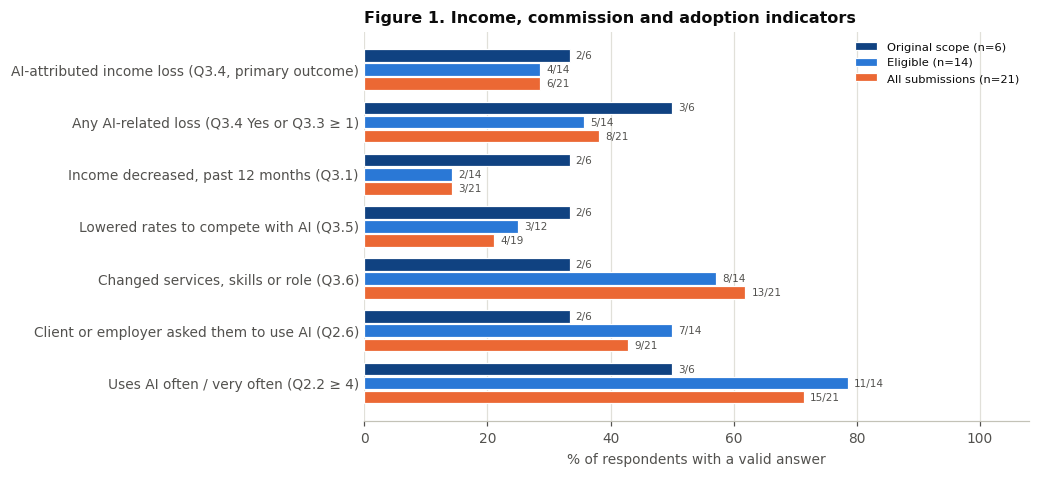

In [11]:
INDICATORS = [  # label, variable, condition (denominator = respondents with a valid answer)
    ("AI-attributed income loss (Q3.4, primary outcome)", "ai_loss",          lambda s: s == 1),
    ("Any AI-related loss (Q3.4 Yes or Q3.3 ≥ 1)",        "any_ai_loss",      lambda s: s == 1),
    ("Lost ≥ 1 commission to AI, past 12 months (Q3.3)",  "any_comm_lost",    lambda s: s == 1),
    ("Income decreased, past 12 months (Q3.1)",           "income_change_ord", lambda s: s < 0),
    ("Lowered rates to compete with AI (Q3.5)",           "lowered_rates",    lambda s: s == 1),
    ("Changed services, skills or role (Q3.6)",           "changed_offering", lambda s: s == 1),
    ("Client or employer asked them to use AI (Q2.6)",    "client_req_ai_yes", lambda s: s == 1),
    ("Uses AI often / very often (Q2.2 ≥ 4)",             "ai_use_freq",      lambda s: s >= 4),
]
def k_n(d, var, f):
    s = d[var].dropna(); return int(f(s).sum()), len(s)
rows = []
for label, var, f in INDICATORS:
    row = [label]
    for gname, d in TABLE_GROUPS.items():
        k, n = k_n(d, var, f); row.append(pct(k, n))
        if gname == G_ELIG:
            lo, hi = wilson(k, n); row.append(f"{lo:.0%}–{hi:.0%}")
    rows.append(row)
cols = ["Indicator", G_CORE, G_ADJ, G_ELIG, "Eligible 95% CI (Wilson)", G_ALL]
outcomes = pd.DataFrame(rows, columns=cols)
outcomes.loc[len(outcomes)] = ["Job security vs 12 months ago, median (1 = much worse, 5 = much better)",
                               f"{core.job_security.median():.1f}", f"{adj.job_security.median():.1f}",
                               f"{an.job_security.median():.1f}", "", f"{alln.job_security.median():.1f}"]
outcomes.to_csv(TAB / f"outcome_indicators_{V}.csv", index=False)
display(outcomes)
print("Q3.5 'Not applicable (salaried)' answers are excluded from that denominator:",
      int(an.lowered_rates.isna().sum()), "eligible respondent(s)")

# Figure 1 — grouped horizontal bars, original scope / eligible / all
FIG1 = [r for r in INDICATORS if r[1] != "any_comm_lost"]
fig, ax = plt.subplots(figsize=(7.8, 4.6))
labels = [l for l, _, _ in FIG1][::-1]
y = np.arange(len(labels)); h = 0.27
for off, gname, col in [(h, G_CORE, C_CORE), (0, G_ELIG, C_ELIG), (-h, G_ALL, C_ALL)]:
    d = GROUPS[gname]; kn = [k_n(d, v, f) for _, v, f in FIG1][::-1]
    share = [100 * k / n for k, n in kn]
    ax.barh(y + off, share, height=h * 0.9, color=col, label=gname, edgecolor="white", linewidth=0.8)
    for yi, s_, (k, n) in zip(y + off, share, kn):
        ax.text(s_ + 1.0, yi, f"{k}/{n}", va="center", fontsize=6.8, color=INK2)
ax.set_yticks(y, labels); ax.set_xlim(0, 108); ax.set_xlabel("% of respondents with a valid answer")
ax.xaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.set_title("Figure 1. Income, commission and adoption indicators")
ax.legend(loc="upper right", fontsize=7.5)
save(fig, "fig1_outcome_indicators"); plt.show()

**Reasoning.** Four of 14 eligible respondents report AI-attributed income loss (Q3.4: 29%, Wilson 95% interval
12%–55%). That is well below the 55% that ICE 1 assumed for planning. Counting any commission lost to AI raises it to
5 of 14.

**The losses sit in the original scope.** Both respondents whose income fell are original-scope artists. Two of the
four Q3.4 "Yes" answers come from the original scope, and one of the two expanded-scope "Yes" answers (R16)
contradicts the rest of that person's answers. Half the original-scope subgroup (3 of 6) reports some AI-related loss,
against 2 of 8 expanded-scope respondents. Median job security is 2 ("a bit nervous") in the original scope and 3.5 in
the expanded scope.

Adaptation is more common than loss: 8 of 14 changed their services, skills or role, and 11 of 14 use AI often or very
often. Adoption is higher in the expanded scope. With *n* = 6, one original-scope respondent moves a percentage by 17
points, so these contrasts are descriptive and nothing more.

### 5.3 Legal-protection and creative-identity items (Sections 4–5)

,Section,Item,% agree Original scope (n=6),% agree Expanded scope (n=8),Median (eligible),Mean (eligible),SD (eligible),% agree Eligible (n=14),% agree All submissions (n=21)
0,Q4 Legal,Aware of legal protections against AI misuse,50%,62%,4.0,3.43,1.55,57%,57%
1,Q4 Legal,Understand SA copyright for AI content,17%,50%,3.0,2.79,1.63,36%,33%
2,Q4 Legal,Current SA law protects creatives adequately,33%,25%,3.0,2.79,1.53,29%,24%
3,Q4 Legal,Would support new AI-and-creators law,100%,75%,5.0,4.43,0.76,86%,86%
4,Q4 Legal,Would know what steps to take,33%,25%,2.5,2.50,1.40,29%,33%
5,Q4 Legal,Industry bodies / unions should do more,67%,88%,5.0,4.36,0.84,79%,76%
6,Q5 Identity,Creative identity is threatened,67%,38%,3.5,3.14,1.61,50%,48%
7,Q5 Identity,AI makes me question my skills' value,33%,0%,3.0,2.57,1.16,14%,24%
8,Q5 Identity,Less motivated to create original work,67%,12%,2.0,2.64,1.50,36%,33%
9,Q5 Identity,Professional pride has changed,50%,25%,3.0,2.93,1.21,36%,33%


saved → outputs/figures/fig2_likert_diverging.png


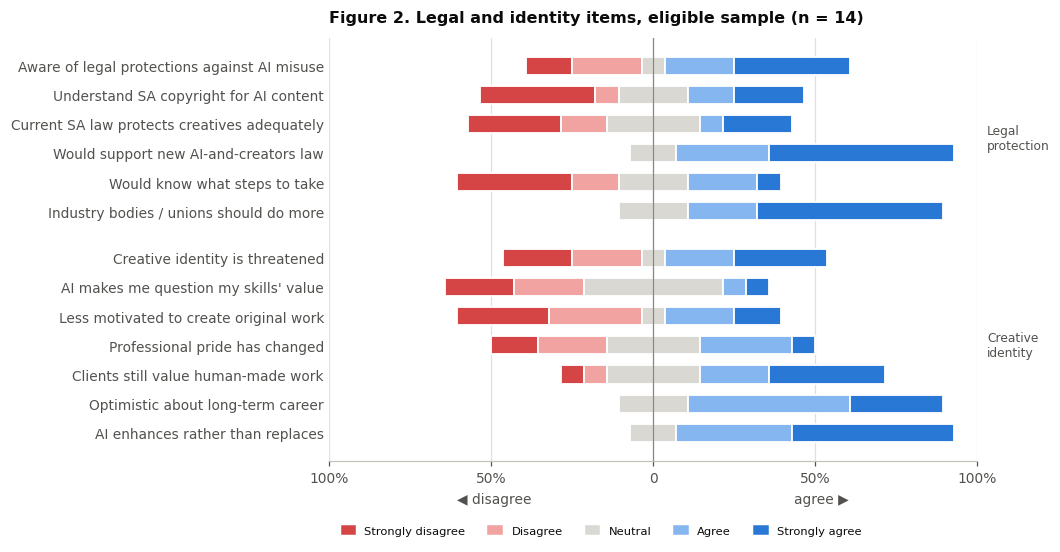

In [12]:
SHORT = {
    "leg_aware": "Aware of legal protections against AI misuse", "leg_understand": "Understand SA copyright for AI content",
    "leg_adequate": "Current SA law protects creatives adequately", "leg_support_new": "Would support new AI-and-creators law",
    "leg_know_steps": "Would know what steps to take", "leg_industry_bodies": "Industry bodies / unions should do more",
    "id_threat": "Creative identity is threatened", "id_skill_value": "AI makes me question my skills' value",
    "id_motivation": "Less motivated to create original work", "id_pride_changed": "Professional pride has changed",
    "id_client_value_human": "Clients still value human-made work", "id_optimism": "Optimistic about long-term career",
    "id_tool_not_replace": "AI enhances rather than replaces",
}
rows = []
for item in LEGAL_ITEMS + ID_ITEMS:
    v = an[item]
    rows.append([("Q4 Legal" if item.startswith("leg") else "Q5 Identity"), SHORT[item],
                 f"{(core[item] >= 4).mean():.0%}", f"{(adj[item] >= 4).mean():.0%}", v.median(), round(v.mean(), 2),
                 round(v.std(ddof=1), 2), f"{(v >= 4).mean():.0%}", f"{(alln[item] >= 4).mean():.0%}"])
likert_summary = pd.DataFrame(rows, columns=["Section", "Item", f"% agree {G_CORE}", f"% agree {G_ADJ}", "Median (eligible)",
                                             "Mean (eligible)", "SD (eligible)", f"% agree {G_ELIG}", f"% agree {G_ALL}"])
likert_summary.to_csv(TAB / f"likert_summary_{V}.csv", index=False)
display(likert_summary)

# Figure 2 — diverging stacked bar, eligible sample, neutral split across zero
items = LEGAL_ITEMS + ID_ITEMS
d = an; n = len(d)
fig, ax = plt.subplots(figsize=(7.6, 5.0))
ypos = []
for i, item in enumerate(items):
    yi = len(items) - i + (0.6 if item.startswith("leg") else 0)  # small gap between sections
    ypos.append(yi)
    share = {k: 100 * (d[item] == k).sum() / n for k in range(1, 6)}
    left = -(share[1] + share[2] + share[3] / 2)
    for k in range(1, 6):
        if share[k] > 0:
            ax.barh(yi, share[k], left=left, height=0.62, color=LIKERT_COLORS[k], edgecolor="white", linewidth=1.2)
        left += share[k]
ax.axvline(0, color=MUTED, linewidth=0.8)
ax.set_yticks(ypos, [SHORT[i] for i in items]); ax.tick_params(axis="y", length=0)
ax.set_xlim(-100, 100); ax.set_xticks([-100, -50, 0, 50, 100], ["100%", "50%", "0", "50%", "100%"])
ax.xaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True); ax.spines["left"].set_visible(False)
ax.set_xlabel("◀ disagree" + " " * 60 + "agree ▶", color=INK2)
ax.text(103, np.mean(ypos[:6]), "Legal\nprotection", fontsize=8, color=INK2, va="center")
ax.text(103, np.mean(ypos[6:]), "Creative\nidentity", fontsize=8, color=INK2, va="center")
handles = [mpl.patches.Patch(color=LIKERT_COLORS[k], label=LIKERT_NAMES[k]) for k in range(1, 6)]
ax.legend(handles=handles, ncol=5, loc="upper center", bbox_to_anchor=(0.42, -0.13), fontsize=7.5, handlelength=1.2)
ax.set_title(f"Figure 2. Legal and identity items, eligible sample (n = {n})", pad=10)
save(fig, "fig2_likert_diverging"); plt.show()

**Reasoning.** The clearest pattern in the dataset is unchanged from v1.1 and holds in both groups. 86% of eligible
respondents (all six original-scope artists) would support new legislation on AI and creators' rights (Q4.4). Yet only
36% say they understand how copyright applies to AI content (Q4.2; one of the six original-scope artists), and 29%
would know what to do if their work were used for training (Q4.5). Eight of 14 support new law without understanding
the current law. **Demand for protection is high; knowledge of existing protection is low.**

On identity, the two groups differ. Original-scope artists are more threatened (Q5.1: 4 of 6 agree, against 3 of 8 in
the expanded scope), less motivated to create original work (Q5.3: 4 of 6 against 1 of 8) and less optimistic about
their career (Q5.6: 3 of 6 against 8 of 8). Every expanded-scope respondent sees AI as enhancing rather than replacing
their work (Q5.7). The eligible averages hide this split, so the final report should present the two groups side by
side. The split is also a finding in itself: the threat is felt most where the work is the image itself.

### 5.4 Items asked in v2 only

Five questions exist only in the revised form, so they describe at most the seven eligible v2 respondents. They are
reported as counts, not percentages. All seven are from the expanded scope, so these items say nothing about the
original-scope artists.

In [13]:
v2e, v2a = an[an.form_version == "v2"], alln[alln.form_version == "v2"]
rows = []
def add_counts(var, label, multi=False):
    for g, d in ((f"v2 eligible (n={len(v2e)})", v2e), (f"v2 all (n={len(v2a)})", v2a)):
        s = df.set_index("resp_id").loc[d.resp_id, var].dropna().astype(str)
        if multi:
            s = s.str.split(r",\s*(?=[A-Z])").explode().str.strip()
        for cat, k in s.value_counts().items():
            rows.append([label, cat, g, int(k)])
add_counts("income_source", "Q1.11 Main source of work or income")
add_counts("other_areas", "Q1.5 Also works in", multi=True)
add_counts("employer_policy", "Q2.8 Employer/client has a written AI policy")
add_counts("role_change", "Q3.8 How AI changed role or team (employed)", multi=True)
v2_items = (pd.DataFrame(rows, columns=["Item", "Answer", "Sample", "n"])
            .pivot_table(index=["Item", "Answer"], columns="Sample", values="n", fill_value=0))
v2_items = v2_items[[f"v2 eligible (n={len(v2e)})", f"v2 all (n={len(v2a)})"]]
disc = v2e.leg_disclosure
v2_items.loc[("Q4.7 Knows what to disclose about AI use (1–5)", "agree (4–5)"), :] = [
    int((disc >= 4).sum()), int((v2a.leg_disclosure >= 4).sum())]
v2_items = v2_items.astype(int)
print(f"Q4.7 median among eligible v2: {disc.median():.0f} (n = {disc.notna().sum()})")
v2_items.to_csv(TAB / f"v2_only_items_{V}.csv")
display(v2_items)

Q4.7 median among eligible v2: 3 (n = 7)


Sample                                                                                              v2 eligible (n=7)  v2 all (n=8)
Item                                           Answer                                                                              
Q1.11 Main source of work or income            A single employer or company (salary)                                3             3
                                               Corporate assignments                                                0             1
                                               Direct clients (individuals or businesses)                           3             3
                                               Online marketplaces, print-on-demand or stock sites                  1             1
Q1.5 Also works in                             Design & built environment                                           4             4
                                               Independent & other                                                  2             2
                                               Marketing & content                                                  4             4
Q2.8 Employer/client has a written AI policy   No                                                                   3             3
                                               Not Sure                                                             1             1
                                               Yes                                                                  3             4
Q3.8 How AI changed role or team (employed)    Fewer junior or entry-level roles                                    1             2
                                               My responsibilities or workload increased                            1             2
                                               My responsibilities or workload reduced                              4             4
                                               No noticeable change                                                 2             2
                                               Team size reduced or positions not replaced                          1             1
Q4.7 Knows what to disclose about AI use (1–5) agree (4–5)                                                          3             4

**Reasoning.** These items describe the seven expanded-scope respondents who answered v2. They are in scope, but seven
people from largely one organisation support counts, not rates. Three of seven say their employer or main client has a
written AI policy (Q2.8), and three of seven know what they must disclose about AI use (Q4.7). On role change (Q3.8),
four report reduced workload. One reports fewer junior or entry-level roles and one a smaller team, which points the
same way as theme T6 in the interviews.

### 5.5 What AI is used for, and which tools respondents meet

v2 offered more options than v1, so v2 respondents can tick more boxes. Options offered only in v2 are therefore shown
as a share of v2 respondents. This is an instrument effect, not evidence that use grew.

In [14]:
rows = []
for label, (_, in_v1) in PURPOSES.items():
    col = "use_" + re.sub(r"\W+", "_", label.lower()).strip("_")
    s = an[col].dropna()
    rows.append(["Purpose (Q2.3)", label, "v1 + v2" if in_v1 else "v2 only", pct(int(s.sum()), len(s))])
for t in TOOLS:
    s = an["tool_" + re.sub(r"\W+", "_", t.lower()).strip("_")]
    rows.append(["Tool seen in the field (Q2.5)", t, "—", pct(int(s.sum()), len(s))])
ai_use = pd.DataFrame(rows, columns=["Question", "Option (harmonised)", "Offered in", f"{G_ELIG}: share of those offered"])
ai_use.to_csv(TAB / f"ai_purposes_tools_{V}.csv", index=False)
display(ai_use)
print("Write-in 'other' purposes:", [t for t in enc.loc[enc.use_other == 1, "purposes_other_text"]])

,Question,Option (harmonised),Offered in,Eligible (n=14): share of those offered
0,Purpose (Q2.3),Ideation / brainstorming,v1 + v2,11/14 (79%)
1,Purpose (Q2.3),Reference images / mood boards,v1 + v2,6/14 (43%)
2,Purpose (Q2.3),Backgrounds / fill work,v1 + v2,5/14 (36%)
3,Purpose (Q2.3),Full finished pieces,v1 + v2,4/14 (29%)
4,Purpose (Q2.3),Concept designs or visualisations,v2 only,5/7 (71%)
5,Purpose (Q2.3),"Captions, copy or scripts",v2 only,6/7 (86%)
6,Purpose (Q2.3),Editing or retouching,v2 only,3/7 (43%)
7,Purpose (Q2.3),Generating video or animation,v2 only,1/7 (14%)
8,Purpose (Q2.3),"Planning, scheduling or reporting",v2 only,5/7 (71%)
9,Purpose (Q2.3),Does not use AI tools,v1 + v2,0/14 (0%)


Write-in 'other' purposes: ['Generating code to automate processes in software', 'Use for comparison', 'Helping in the creation of movement for the characters']


## 6. Bivariate association tests (SQ2 · H1–H3)

ICE 1 §3.4 rule: chi-square where every expected cell count is ≥ 5, otherwise Fisher's exact test, with Cramér's V (φ
for a 2×2 table) alongside *p*. Each predictor is dichotomised at a cut-point set before testing. Odds ratios use the
Haldane–Anscombe +0.5 correction when a cell is empty. H3 is tested twice, as v1.1 recommended: with awareness (Q4.1,
H3a) and with working knowledge (mean of Q4.2 and Q4.5, H3b). With five tests the Bonferroni threshold is α = 0.01.
**At this sample size the tests describe the data; they cannot confirm or reject H1–H3.**

In [15]:
an["leg_knowledge"] = an[["leg_understand", "leg_know_steps"]].mean(axis=1)
alln["leg_knowledge"] = alln[["leg_understand", "leg_know_steps"]].mean(axis=1)
EXPOSURES = {
    "H1a  Uses AI often/very often (Q2.2 ≥ 4)":           lambda d: d.ai_use_freq >= 4,
    "H1b  Sees high adoption in field (Q2.4 ≥ 4)":        lambda d: d.peer_adoption >= 4,
    "H2   Early/mid-career (vs established)":             lambda d: d.career_grp != "Established",
    "H3a  Aware of legal protections (Q4.1 ≥ 4)":         lambda d: d.leg_aware >= 4,
    "H3b  Working legal knowledge (mean Q4.2, Q4.5 ≥ 4)": lambda d: d.leg_knowledge >= 4,
}
def test_2x2(x, yv):
    t = pd.crosstab(x, yv).reindex(index=[1, 0], columns=[1, 0], fill_value=0).to_numpy()
    (a, b), (c, e) = t
    if (t.sum(axis=0) == 0).any() or (t.sum(axis=1) == 0).any():
        return f"{a}/{a+b}", f"{c}/{c+e}", "not testable", np.nan, np.nan, np.nan
    chi2, p_chi, _, expected = stats.chi2_contingency(t, correction=False)
    use_fisher = expected.min() < 5
    p = stats.fisher_exact(t)[1] if use_fisher else p_chi
    ha = 0.5 if 0 in t else 0
    orr = ((a + ha) * (e + ha)) / ((b + ha) * (c + ha))
    return f"{a}/{a+b}", f"{c}/{c+e}", "Fisher's exact" if use_fisher else "χ²", round(p, 3), round(orr, 2), round(np.sqrt(chi2 / t.sum()), 2)
rows = []
for hyp, f in EXPOSURES.items():
    for gname in (G_ELIG, G_ALL):
        d = an if gname == G_ELIG else alln
        rows.append([hyp, gname, len(d), *test_2x2(f(d).astype(int), d.ai_loss.astype(int))])
bivariate = pd.DataFrame(rows, columns=["Hypothesis / predictor", "Sample", "n", "Loss | exposed", "Loss | not exposed",
                                        "Test", "p (two-sided)", "OR", "Cramér's V"])
bivariate.to_csv(TAB / f"bivariate_tests_{V}.csv", index=False)
display(bivariate)

# Sensitivity: the broad outcome (Q3.4 Yes OR any commission lost to AI), eligible sample
sens = pd.DataFrame([[hyp, *test_2x2(f(an).astype(int), an.any_ai_loss.astype(int))] for hyp, f in EXPOSURES.items()],
                    columns=["Hypothesis / predictor", "Loss | exposed", "Loss | not exposed", "Test", "p", "OR", "Cramér's V"])
print("Sensitivity — broad outcome, eligible sample:"); display(sens)
sens.to_csv(TAB / f"bivariate_sensitivity_broad_outcome_{V}.csv", index=False)

# Who are the events? With so few, every contrast is defined by the same handful of people.
events = alln.loc[alln.any_ai_loss == 1, ["resp_id", "form_version", "scope_tier", "subfield_grp", "career_grp",
                                          "ai_use_freq", "peer_adoption", "leg_aware", "ai_loss", "comm_lost_ord"]]
events.insert(1, "eligible", events.resp_id.map(scr.set_index("resp_id").eligible))
print("Respondents reporting any AI-related loss (Q3.4 = Yes or Q3.3 ≥ 1):"); display(events)
print(f"Bonferroni threshold for the five hypothesis tests: α = 0.05 / 5 = {0.05 / 5:.3f}")
print("Q2.4 among eligible v2 respondents:", an.loc[an.form_version == "v2", "peer_adoption"].value_counts().to_dict())

,Hypothesis / predictor,Sample,n,Loss | exposed,Loss | not exposed,Test,p (two-sided),OR,Cramér's V
0,H1a Uses AI often/very often (Q2.2 ≥ 4),Eligible (n=14),14,2/11,2/3,Fisher's exact,0.176,0.11,0.44
1,H1a Uses AI often/very often (Q2.2 ≥ 4),All submissions (n=21),21,2/15,4/6,Fisher's exact,0.031,0.08,0.53
2,H1b Sees high adoption in field (Q2.4 ≥ 4),Eligible (n=14),14,3/10,1/4,Fisher's exact,1.000,1.29,0.05
3,H1b Sees high adoption in field (Q2.4 ≥ 4),All submissions (n=21),21,4/14,2/7,Fisher's exact,1.000,1.00,0.00
4,H2 Early/mid-career (vs established),Eligible (n=14),14,4/9,0/5,Fisher's exact,0.221,9.00,0.47
5,H2 Early/mid-career (vs established),All submissions (n=21),21,5/11,1/10,Fisher's exact,0.149,7.50,0.39
6,H3a Aware of legal protections (Q4.1 ≥ 4),Eligible (n=14),14,1/8,3/6,Fisher's exact,0.245,0.14,0.41
7,H3a Aware of legal protections (Q4.1 ≥ 4),All submissions (n=21),21,2/12,4/9,Fisher's exact,0.331,0.25,0.30
8,"H3b Working legal knowledge (mean Q4.2, Q4.5 ≥ 4)",Eligible (n=14),14,1/4,3/10,Fisher's exact,1.000,0.78,0.05
9,"H3b Working legal knowledge (mean Q4.2, Q4.5 ≥ 4)",All submissions (n=21),21,1/6,5/15,Fisher's exact,0.623,0.40,0.17


Sensitivity — broad outcome, eligible sample:


,Hypothesis / predictor,Loss | exposed,Loss | not exposed,Test,p,OR,Cramér's V
0,H1a Uses AI often/very often (Q2.2 ≥ 4),3/11,2/3,Fisher's exact,0.505,0.19,0.34
1,H1b Sees high adoption in field (Q2.4 ≥ 4),4/10,1/4,Fisher's exact,1.000,2.00,0.14
2,H2 Early/mid-career (vs established),5/9,0/5,Fisher's exact,0.086,13.44,0.56
3,H3a Aware of legal protections (Q4.1 ≥ 4),2/8,3/6,Fisher's exact,0.580,0.33,0.26
4,"H3b Working legal knowledge (mean Q4.2, Q4.5 ≥ 4)",1/4,4/10,Fisher's exact,1.000,0.50,0.14


Respondents reporting any AI-related loss (Q3.4 = Yes or Q3.3 ≥ 1):


,resp_id,eligible,form_version,scope_tier,subfield_grp,career_grp,ai_use_freq,peer_adoption,leg_aware,ai_loss,comm_lost_ord
1,R02,True,v1,original,Animation & motion,Early,5,5,5,0,2
2,R03,True,v1,original,Illustration & concept art,Early,2,1,1,1,1
3,R04,True,v1,original,Illustration & concept art,Mid,3,4,2,1,2
10,R11,False,v1,original,Animation & motion,Established,4,4,5,0,2
12,R13,False,v1,original,Illustration & concept art,Mid,3,5,4,1,4
14,R15,True,v2,expanded,"Graphic, brand & UI/UX design",Early,4,5,2,1,2
15,R16,True,v2,expanded,Social media & content,Mid,5,5,4,1,0
19,R20,False,v2,expanded,Independent & platform-based,Established,2,3,1,1,0


Bonferroni threshold for the five hypothesis tests: α = 0.05 / 5 = 0.010
Q2.4 among eligible v2 respondents: {5: 6, 4: 1}


**Reasoning.** No test supports H1–H3 in the eligible sample (all *p* ≥ 0.17), and none would survive the Bonferroni
threshold of 0.01. The event table shows why the tests cannot settle anything: four people define every contrast.

Two directions are still worth carrying into the discussion as observations, not findings:

- **H1 runs the wrong way.** Loss is more common among *low* AI users (2 of 3 eligible; 4 of 6 across all submissions,
  *p* = 0.031) than among frequent users (2 of 11; 2 of 15). The planned hypothesis expects the opposite. One
  reading to test in the discussion: exposure may depend on whether clients can replace the work, not on whether the
  creative adopts the tools.
- **H2 is in the predicted direction.** All four eligible events are early or mid-career (4 of 9, against 0 of 5
  established). With the broad outcome it is 5 of 9 against 0 of 5 (*p* = 0.086).

H3 shows nothing with either measure. Q2.4 (adoption in the field) cannot discriminate in v2: six of the seven eligible
v2 respondents chose the top category.

## 7. Modelling gates (ICE 1 §3.2 and §4.2) — final position

ICE 1 set a floor of *n* ≥ 50 for the penalised logistic regression and the depth-limited tree (about 4.5 events per
parameter at the planned prevalence), and a contingency for the case where the survey closes below it: abandon
multivariable modelling, report descriptive and bivariate results only, reframe SQ2 as association rather than
prediction, and state the limitation prominently. Recruitment has now closed, so the gate is final.

In [16]:
N_FLOOR, N_TARGET, N_PARAMS = 50, 80, 6
rows = []
for gname, d in GROUPS.items():
    n, ev = len(d), int(d.ai_loss.sum()); prev = ev / n
    rows.append([gname, n, ev, f"{prev:.0%}", round(ev / N_PARAMS, 2),
                 "RUN" if n >= N_FLOOR else "ABANDONED — ICE 1 contingency (n < 50 at close)",
                 f"{max(prev, 1 - prev):.0%} : {min(prev, 1 - prev):.0%}",
                 "TRIGGERED" if max(prev, 1 - prev) > 0.80 else "not triggered"])
gates = pd.DataFrame(rows, columns=["Sample", "n", "Events (Q3.4 = Yes)", "Prevalence", "Events per parameter (6)",
                                    "Penalised regression + tree", "Outcome split", "Tier-2 ordinal model (> 80:20)"])
gates.to_csv(TAB / f"modelling_gates_{V}.csv", index=False)
display(gates)
need = int(np.ceil(5 * N_PARAMS / an.ai_loss.mean()))
print(f"At the observed eligible prevalence ({an.ai_loss.mean():.0%}), five events per parameter would need n ≈ {need}; "
      f"the ICE 1 target of {N_TARGET} would have given ~{an.ai_loss.mean() * N_TARGET:.0f} events "
      f"({an.ai_loss.mean() * N_TARGET / N_PARAMS:.1f} per parameter).")

# The specification stays on record, so the final report can state exactly what was not estimated
PREDICTORS = pd.DataFrame([
    ["ai_use_freq", "Q2.2 own use (1–5)", "H1"], ["peer_adoption", "Q2.4 adoption in field (1–5)", "H1"],
    ["early_mid", "Early/mid-career (0/1)", "H2"], ["leg_aware", "Q4.1 awareness (1–5)", "H3"],
    ["animation", "Animation & motion sub-field (0/1)", "covariate"], ["independent", "Independent / own business (0/1)", "covariate"],
], columns=["Parameter", "Definition", "Role"])
PREDICTORS["Status"] = "specified in ICE 1; not estimated"
display(PREDICTORS)

,Sample,n,Events (Q3.4 = Yes),Prevalence,Events per parameter (6),Penalised regression + tree,Outcome split,Tier-2 ordinal model (> 80:20)
0,Original scope (n=6),6,2,33%,0.33,ABANDONED — ICE 1 contingency (n < 50 at close),67% : 33%,not triggered
1,Eligible (n=14),14,4,29%,0.67,ABANDONED — ICE 1 contingency (n < 50 at close),71% : 29%,not triggered
2,All submissions (n=21),21,6,29%,1.00,ABANDONED — ICE 1 contingency (n < 50 at close),71% : 29%,not triggered


At the observed eligible prevalence (29%), five events per parameter would need n ≈ 105; the ICE 1 target of 80 would have given ~23 events (3.8 per parameter).


,Parameter,Definition,Role,Status
0,ai_use_freq,Q2.2 own use (1–5),H1,specified in ICE 1; not estimated
1,peer_adoption,Q2.4 adoption in field (1–5),H1,specified in ICE 1; not estimated
2,early_mid,Early/mid-career (0/1),H2,specified in ICE 1; not estimated
3,leg_aware,Q4.1 awareness (1–5),H3,specified in ICE 1; not estimated
4,animation,Animation & motion sub-field (0/1),covariate,specified in ICE 1; not estimated
5,independent,Independent / own business (0/1),covariate,specified in ICE 1; not estimated


**Reasoning.** The rule settles it. With 14 eligible respondents and 4 events (0.67 per parameter), the penalised
regression and decision tree are **abandoned**, as the ICE 1 contingency prescribes when the survey closes below 50.
This is no longer a deferral, because recruitment has closed. SQ2 is answered by the descriptive and bivariate results
and explained by the interviews, and ICE 3 should state this prominently.

The prevalence matters for the limitations section. At the observed 29%, five events per parameter would need about
105 eligible respondents, so even the ICE 1 target of 80 would not have supported the six-parameter model. Any future
study of this outcome should plan with a lower prevalence or fewer parameters.

## 8. Qualitative strand — preparing the text corpus

**Survey free text (Q6.1–Q6.4).** ICE 1 removes non-responsive answers from the *text corpus only*: blanks, answers
under three words, and answers unrelated to the question. Following ICE 1's default of keeping borderline cases, short
answers that address the question (*"Copyrighting"*, *"unsure"*) are **kept and logged**. Bare non-answers are removed.

**Interviews.** The machine transcripts for P4–P11 had missing or wrong speaker labels, so every block was attributed
to the interviewer or the participant by reading it. Blocks that merge both speakers are labelled `MIX`, and off-topic
asides `OFF`; both are left out of coding. Each participant turn of eight words or more is one segment. Three shorter
turns that answer a guide question directly are kept and logged, mirroring the survey rule. Turns before the formal
start (setup and consent) are left out. Two scope rules apply: P3's GIS and logistics passages (as in v1.1), and P10's
passages on arts-funding administration, which do not concern AI.

In [17]:
TEXT_COLS = {"txt_work_income": "Q6.1 Work & income", "txt_identity": "Q6.2 Identity & purpose",
             "txt_protections": "Q6.3 Protections needed", "txt_other": "Q6.4 Anything else"}
NON_CONTENT = re.compile(r"^(no|nope|none|n/?a|nothing( yet)?|not really|no\W*not that much|not at the moment)\W*$", re.I)
elig_map = scr.set_index("resp_id").eligible; tier_map = enc.set_index("resp_id").scope_tier
rows = []
for _, r in df.iterrows():
    for col, qlab in TEXT_COLS.items():
        text = "" if pd.isna(r[col]) else re.sub(r"\s+", " ", str(r[col])).strip()
        nw = len(text.split())
        status = ("removed: blank" if not text else "removed: non-answer" if NON_CONTENT.match(text)
                  else "kept: short but on-topic (logged)" if nw < 3 else "kept")
        rows.append(dict(seg_id=f"S:{r.resp_id}:{col}", source="Survey", unit=r.resp_id, question=qlab,
                         eligible=bool(elig_map[r.resp_id]), tier=tier_map[r.resp_id], text=text, words=nw, status=status))
survey_text = pd.DataFrame(rows)
display(survey_text.groupby("status").size().rename("responses").reset_index())
display(survey_text.loc[survey_text.status.str.contains("short"), ["seg_id", "text"]])
survey_corpus = survey_text[survey_text.status.str.startswith("kept")].copy()

INTERVIEWS = pd.DataFrame([  # order = order conducted; profiles are deliberately general (de-identification)
    dict(pid="P1",  date="2026-10-12", time="—",     minutes=21, mode="Teams", guide="Track A",
         profile="Owner of a PR agency producing AI-assisted design and video", tier="expanded"),
    dict(pid="P3",  date="2026-10-13", time="10:09", minutes=35, mode="online", guide="Track A",
         profile="Retired architect / urban designer; uses AI rendering", tier="expanded"),
    dict(pid="P2",  date="2026-10-14", time="—",     minutes=33, mode="Teams", guide="Track A",
         profile="Character animator / supervisor at a South African animation studio", tier="original"),
    dict(pid="P4",  date="2026-10-19", time="15:38", minutes=34, mode="face-to-face", guide="adapted (design/IT)",
         profile="Graphics and systems designer, video editor; runs a small design business", tier="expanded"),
    dict(pid="P5",  date="2026-10-19", time="16:15", minutes=35, mode="face-to-face", guide="adapted (IT/games)",
         profile="IT coordinator and independent game developer/designer", tier="expanded"),
    dict(pid="P6",  date="2026-10-20", time="11:42", minutes=36, mode="face-to-face", guide="adapted (HR/social media)",
         profile="HR and admin professional with social media and content duties (NPC)", tier="peripheral"),
    dict(pid="P7",  date="2026-10-20", time="12:50", minutes=34, mode="face-to-face", guide="adapted (software/UX)",
         profile="Software developer and founder; does own UX/UI design", tier="expanded"),
    dict(pid="P8",  date="2026-10-20", time="15:39", minutes=21, mode="face-to-face", guide="adapted (social media)",
         profile="In-house social media manager and content creator (NPC); 6 months in role", tier="expanded"),
    dict(pid="P9",  date="2026-10-23", time="14:55", minutes=23, mode="face-to-face", guide="adapted (social media)",
         profile="Social media, graphic design and event planning (NPC)", tier="expanded"),
    dict(pid="P10", date="2026-11-03", time="13:53", minutes=54, mode="face-to-face", guide="stakeholder",
         profile="Arts specialist (performing arts) in provincial government", tier="stakeholder"),
    dict(pid="P11", date="2026-11-03", time="16:25", minutes=23, mode="Teams", guide="adapted (IT)",
         profile="IT service desk officer; former full-stack developer", tier="peripheral"),
])
# Time = the time written in the transcript header. P11's header says 23 October; the recording file is stamped
# 3 November 16:01, which matches the header time of 16:25 after a 23-minute interview, so 3 November is used here.
INTERVIEWS["order"] = range(1, len(INTERVIEWS) + 1)
TIER = INTERVIEWS.set_index("pid").tier.to_dict()
TIER_ORDER = ["original", "expanded", "peripheral", "stakeholder"]
INTERVIEW_START = {"P1": "02:40", "P2": "03:38", "P3": "00:48", "P4": "02:04", "P5": "01:58", "P6": "01:35",
                   "P7": "00:44", "P8": "01:40", "P9": "01:38", "P10": "02:13", "P11": "02:19"}
OUT_OF_SCOPE = {"P3":  [("01:26", "03:29"), ("06:10", "09:30"), ("26:36", "99:99")],   # GIS / urban modelling / logistics
                "P10": [("11:57", "18:55"), ("39:52", "45:11")]}                        # arts-funding administration
KEEP_SHORT = {"P4@22:14": "'makes studying sound pointless'", "P8@16:50": "answer to the legal-knowledge question",
              "P9@16:53": "answer to the legal-knowledge question"}
MIN_WORDS = 8

def load_transcript(pid):
    rows = []
    for line in (DATA / f"{pid}_transcript_deid.txt").read_text(encoding="utf-8").splitlines():
        if m := re.match(r"\[(\d\d:\d\d)\] (\w+): (.*)", line):
            rows.append(dict(pid=pid, ts=m.group(1), speaker=m.group(2), text=m.group(3)))
    return pd.DataFrame(rows)

segs, blocks = [], []
for pid in INTERVIEWS.pid:
    t = load_transcript(pid)
    blocks.append(t.speaker.map(lambda s: s if s in ("INT", "MIX", "OFF") else "participant").value_counts().rename(pid))
    t = t[(t.speaker == pid) & (t.ts >= INTERVIEW_START[pid])].copy()
    t["seg_id"] = t.pid + "@" + t.ts
    t["words"] = t.text.str.split().str.len()
    t["in_scope"] = ~t.ts.apply(lambda ts: any(a <= ts <= b for a, b in OUT_OF_SCOPE.get(pid, [])))
    t["status"] = np.select([~t.in_scope, t.seg_id.isin(KEEP_SHORT), t.words < MIN_WORDS],
                            ["excluded: out of scope", "kept: short but on-topic (logged)", "excluded: < 8 words"], "kept")
    segs.append(t)
interview_turns = pd.concat(segs, ignore_index=True)
assert interview_turns.seg_id.is_unique and set(KEEP_SHORT) <= set(interview_turns.seg_id)
block_counts = pd.concat(blocks, axis=1).T.fillna(0).astype(int)
INTERVIEWS = (INTERVIEWS.merge(interview_turns.groupby("pid").status.value_counts().unstack(fill_value=0).reset_index(), on="pid")
              .merge(block_counts[["MIX", "OFF"]].rename(columns={"MIX": "mixed-speaker blocks", "OFF": "off-topic blocks"}),
                     left_on="pid", right_index=True))
INTERVIEWS.to_csv(TAB / f"interview_register_{V}.csv", index=False)
display(INTERVIEWS)
print("Interviews by scope tier:", INTERVIEWS.tier.value_counts().reindex(TIER_ORDER).to_dict())

interview_corpus = (interview_turns[interview_turns.status.str.startswith("kept")]
                    .rename(columns={"pid": "unit"})
                    .assign(source="Interview", question="Interview", eligible=np.nan, tier=lambda d: d.unit.map(TIER))
                    [["seg_id", "source", "unit", "question", "eligible", "tier", "text", "words"]])
corpus = pd.concat([survey_corpus.drop(columns="status"), interview_corpus], ignore_index=True)
print(f"Text corpus: {len(survey_corpus)} survey responses (of {len(survey_text)}) + {len(interview_corpus)} interview segments")

usable_eligible = int((survey_corpus.eligible == True).sum())
print(f"Tier-2 TF-IDF trigger (≥ 50 usable free-text responses): eligible = {usable_eligible}, all = {len(survey_corpus)} "
      f"→ {'RUN' if usable_eligible >= 50 else 'NOT TRIGGERED — TF-IDF not run'}")

,status,responses
0,kept,64
1,kept: short but on-topic (logged),6
2,removed: blank,3
3,removed: non-answer,11


,seg_id,text
9,S:R03:txt_identity,Poor quality
22,S:R06:txt_protections,Copyright protection
41,S:R11:txt_identity,Highly impacted
66,S:R17:txt_protections,unsure
74,S:R19:txt_protections,Copyrighting
77,S:R20:txt_identity,Not threatened


,pid,date,time,minutes,mode,guide,profile,tier,order,excluded: < 8 words,excluded: out of scope,kept,kept: short but on-topic (logged),mixed-speaker blocks,off-topic blocks
0,P1,2026-10-12,—,21,Teams,Track A,Owner of a PR agency producing AI-assisted design and video,expanded,1,15,0,17,0,0,0
1,P3,2026-10-13,10:09,35,online,Track A,Retired architect / urban designer; uses AI rendering,expanded,2,4,30,31,0,0,0
2,P2,2026-10-14,—,33,Teams,Track A,Character animator / supervisor at a South African animation studio,original,3,13,0,32,0,0,0
3,P4,2026-10-19,15:38,34,face-to-face,adapted (design/IT),"Graphics and systems designer, video editor; runs a small design business",expanded,4,3,0,48,1,0,0
4,P5,2026-10-19,16:15,35,face-to-face,adapted (IT/games),IT coordinator and independent game developer/designer,expanded,5,4,0,44,0,0,0
5,P6,2026-10-20,11:42,36,face-to-face,adapted (HR/social media),HR and admin professional with social media and content duties (NPC),peripheral,6,10,0,57,0,2,0
6,P7,2026-10-20,12:50,34,face-to-face,adapted (software/UX),Software developer and founder; does own UX/UI design,expanded,7,1,0,62,0,2,3
7,P8,2026-10-20,15:39,21,face-to-face,adapted (social media),In-house social media manager and content creator (NPC); 6 months in role,expanded,8,8,0,16,1,7,0
8,P9,2026-10-23,14:55,23,face-to-face,adapted (social media),"Social media, graphic design and event planning (NPC)",expanded,9,11,0,40,1,2,0
9,P10,2026-11-03,13:53,54,face-to-face,stakeholder,Arts specialist (performing arts) in provincial government,stakeholder,10,4,22,66,0,0,0


Interviews by scope tier: {'original': 1, 'expanded': 7, 'peripheral': 2, 'stakeholder': 1}
Text corpus: 70 survey responses (of 84) + 467 interview segments
Tier-2 TF-IDF trigger (≥ 50 usable free-text responses): eligible = 48, all = 70 → NOT TRIGGERED — TF-IDF not run


**Reasoning.** 70 of the 84 survey text answers are usable: 14 are blank or bare non-answers, and six short on-topic
answers are kept under the borderline rule. Eligible respondents supply 48 usable answers. That is just below the 50
that triggers TF-IDF, so the Tier-2 term ranking is not run, as ICE 1 specifies.

From the interviews, 467 participant segments are coded. Two scope rules remove 52 segments: P3's GIS and logistics
passages (30) and P10's passages on arts-funding administration (22). Fifteen blocks merge both speakers (seven of them
in P8), and three are off-topic asides. All of these are excluded, so P8 contributes only 17 segments. P8's thin data
reflects a short interview and a poor transcript, and it should not be read as an absence of views.

### 8.1 Interview closing check: the survey items asked aloud

From P5 onwards the interviewer closed by asking four survey items aloud (Q2.2 use, Q3.1 income change, Q3.4
AI-attributed loss, Q3.8 role or team change). The answers are recorded as transcribed. Unclear or merged answers are
marked as such rather than guessed. They are a small cross-check on the survey, not extra survey responses.

In [18]:
QUICK = pd.DataFrame([
    ["P4",  "not asked",            "not asked",               "not asked",                 "not asked"],
    ["P5",  "4 (games) / 1 (IT)",   "not applicable",          "Yes",                       "not asked"],
    ["P6",  "3",                    "stayed the same",         "unclear (merged block)",    "unclear (merged block)"],
    ["P7",  "4",                    "unclear (merged block)",  "unclear (merged block)",    "less work; team reduced"],
    ["P8",  "4",                    "unclear (merged block)",  "No (in merged block)",      "team size the same"],
    ["P9",  "3–4",                  "stayed the same",         "No",                        "no change overall"],
    ["P10", "n/a (stakeholder)",    "n/a",                     "n/a",                       "n/a"],
    ["P11", "1 ('I don't use it')", "not asked",               "not asked",                 "no change"],
], columns=["pid", "Q2.2 use (1–5)", "Q3.1 income, 12 months", "Q3.4 AI-attributed loss", "Q3.8 role / team"])
QUICK.insert(1, "tier", QUICK.pid.map(TIER))
QUICK.to_csv(TAB / f"interview_quick_check_{V}.csv", index=False)
display(QUICK)

,pid,tier,Q2.2 use (1–5),"Q3.1 income, 12 months",Q3.4 AI-attributed loss,Q3.8 role / team
0,P4,expanded,not asked,not asked,not asked,not asked
1,P5,expanded,4 (games) / 1 (IT),not applicable,Yes,not asked
2,P6,peripheral,3,stayed the same,unclear (merged block),unclear (merged block)
3,P7,expanded,4,unclear (merged block),unclear (merged block),less work; team reduced
4,P8,expanded,4,unclear (merged block),No (in merged block),team size the same
5,P9,expanded,3–4,stayed the same,No,no change overall
6,P10,stakeholder,n/a (stakeholder),n/a,n/a,n/a
7,P11,peripheral,1 ('I don't use it'),not asked,not asked,no change


### 8.2 Interview-guide coverage

The supplied guide holds **Track A** (digital artists and animators, A0–A13) and **Track B** (legal and policy experts).
P1–P3 used Track A, so their coverage is recorded question by question, as in v1.1. P4–P11 were interviewed with
adapted scripts for their roles (design and IT, social media, a stakeholder script for P10) that are not in the supplied
guide. Their coverage is therefore recorded at **section** level, using the sections all the scripts share. The section
anchors are also used in 9.1 to locate each coded segment in the interview.

In [19]:
GUIDE = {  # Track A: digital artists & animators (A12.5 is blank in the guide and is ignored)
    "A0":  ("Opening",               "Career, how you got started, a typical project"),
    "A1":  ("Income & displacement", "How professional work has changed since generative AI"),
    "A2":  ("Income & displacement", "Clients, commissions or work lost to AI, with an example"),
    "A3":  ("Income & displacement", "Changes in how clients negotiate pricing"),
    "A4":  ("Income & displacement", "Changes to process, pricing or service offering"),
    "A5":  ("Income & displacement", "Expected effect on income or career in the next few years"),
    "A6":  ("Creative identity",     "Effect on identity as a creative professional"),
    "A7":  ("Creative identity",     "Effect on feelings about own skills / meaning of work"),
    "A8":  ("Creative identity",     "Threat, tool or something in between, and why"),
    "A9":  ("Legal protection",      "Knowledge of SA legal protections, particularly regarding AI"),
    "A10": ("Legal protection",      "Most urgently needed legal or industry protections"),
    "A11": ("Legal protection",      "Formal or informal action taken in response to AI concerns"),
    "A12": ("Client perception",     "How SA clients and studios value human-made vs AI work"),
    "A13": ("Closing",               "Anything important not yet covered"),
}
SECTIONS = ["Opening", "AI use & exposure", "Income & displacement", "Creative identity", "Legal protection",
            "Client perception", "Closing check", "Closing"]

#            pid   question  status              timestamp  note
COVERAGE = [
    ("P1", "A0", "asked", "02:42", ""), ("P1", "A1", "adapted", "04:33", "asked about work before AI rather than how it changed"),
    ("P1", "A2", "asked", "06:57", ""), ("P1", "A3", "asked", "09:10", ""), ("P1", "A4", "asked", "09:57", ""),
    ("P1", "A5", "asked", "10:57", ""), ("P1", "A6", "skipped", "12:38", "judged already answered"),
    ("P1", "A7", "adapted", "13:02", "re-asked at 14:04 with a positively framed prompt"),
    ("P1", "A8", "skipped", "16:14", "judged already answered"), ("P1", "A9", "asked", "16:14", ""),
    ("P1", "A10", "not asked", "", ""), ("P1", "A11", "asked", "17:07", ""),
    ("P1", "A12", "not asked", "", "replaced by an unscripted question on work quality (17:47)"), ("P1", "A13", "asked", "19:24", ""),
    ("P2", "A0", "asked", "03:28", ""), ("P2", "A1", "asked", "07:21", ""), ("P2", "A2", "asked", "11:11", ""),
    ("P2", "A3", "asked", "12:58", ""), ("P2", "A4", "not asked", "", "process change partly covered under A1"),
    ("P2", "A5", "asked", "17:10", ""), ("P2", "A6", "skipped", "21:47", "judged already answered"),
    ("P2", "A7", "asked", "21:47", ""), ("P2", "A8", "asked", "24:07", ""), ("P2", "A9", "asked", "25:35", ""),
    ("P2", "A10", "asked", "26:38", ""), ("P2", "A11", "asked", "27:55", ""),
    ("P2", "A12", "started, dropped", "29:28", "judged not applicable: studio serves international clients"),
    ("P2", "A13", "asked", "30:08", ""),
    ("P3", "A0", "asked", "00:34", ""), ("P3", "A1", "not asked", "", "covered within the A0 career account"),
    ("P3", "A2", "adapted", "09:12", "re-framed for a city department"), ("P3", "A3", "not asked", "", ""),
    ("P3", "A4", "not asked", "", ""), ("P3", "A5", "not asked", "", ""), ("P3", "A6", "asked", "10:50", ""),
    ("P3", "A7", "not asked", "", ""), ("P3", "A8", "asked", "15:26", ""),
    ("P3", "A9", "adapted", "18:21", "broadened to laws architects must follow"),
    ("P3", "A10", "not asked", "", "raised unprompted at 21:31"), ("P3", "A11", "not asked", "", ""),
    ("P3", "A12", "not asked", "", ""), ("P3", "A13", "asked", "24:14", ""),
]
UNSCRIPTED = [("P1", "17:47", "Unscripted: work quality vs before AI")]
coverage = pd.DataFrame(COVERAGE, columns=["pid", "q", "status", "ts", "note"])
assert len(coverage) == 3 * len(GUIDE) and set(coverage.q) == set(GUIDE)
coverage["section"] = coverage.q.map(lambda q: GUIDE[q][0])
coverage["covered"] = coverage.status.isin(["asked", "adapted"])
coverage.to_csv(TAB / f"interview_guide_coverage_trackA_{V}.csv", index=False)
status_matrix = coverage.pivot(index="q", columns="pid", values="status").reindex(list(GUIDE))[["P1", "P2", "P3"]]
status_matrix.insert(0, "Section", [GUIDE[q][0] for q in status_matrix.index])
display(status_matrix)

# Section anchors for P4–P11: (pid, timestamp of the interviewer's first prompt in the section, section)
SECTION_ANCHORS = [
    ("P4", "01:48", "Opening"), ("P4", "04:55", "AI use & exposure"), ("P4", "11:20", "Income & displacement"),
    ("P4", "19:14", "Creative identity"), ("P4", "22:17", "Legal protection"), ("P4", "30:07", "Client perception"),
    ("P4", "33:17", "Closing"),
    ("P5", "01:27", "Opening"), ("P5", "05:48", "AI use & exposure"), ("P5", "11:07", "Income & displacement"),
    ("P5", "19:09", "Creative identity"), ("P5", "23:29", "Legal protection"), ("P5", "30:15", "Client perception"),
    ("P5", "32:32", "Closing check"), ("P5", "33:49", "Closing"),
    ("P6", "01:20", "Opening"), ("P6", "10:53", "AI use & exposure"), ("P6", "14:01", "Income & displacement"),
    ("P6", "22:00", "Creative identity"), ("P6", "24:44", "Legal protection"), ("P6", "30:55", "Client perception"),
    ("P6", "34:25", "Closing check"), ("P6", "35:28", "Closing"),
    ("P7", "00:35", "Opening"), ("P7", "05:11", "AI use & exposure"), ("P7", "09:12", "Income & displacement"),
    ("P7", "17:03", "Creative identity"), ("P7", "19:31", "Legal protection"), ("P7", "26:45", "Client perception"),
    ("P7", "28:45", "Closing check"), ("P7", "30:05", "Closing"),
    ("P8", "01:26", "Opening"), ("P8", "05:06", "AI use & exposure"), ("P8", "07:35", "Income & displacement"),
    ("P8", "14:50", "Creative identity"), ("P8", "16:17", "Legal protection"), ("P8", "19:09", "Closing check"),
    ("P8", "20:09", "Closing"),
    ("P9", "01:28", "Opening"), ("P9", "04:39", "AI use & exposure"), ("P9", "09:49", "Income & displacement"),
    ("P9", "13:45", "Creative identity"), ("P9", "16:43", "Legal protection"), ("P9", "18:57", "Client perception"),
    ("P9", "21:39", "Closing check"), ("P9", "22:40", "Closing"),
    ("P10", "01:53", "Opening"), ("P10", "11:01", "Income & displacement"), ("P10", "19:11", "AI use & exposure"),
    ("P10", "22:07", "Income & displacement"), ("P10", "27:24", "AI use & exposure"), ("P10", "29:23", "Creative identity"),
    ("P10", "32:28", "Client perception"), ("P10", "33:31", "Legal protection"), ("P10", "48:37", "Closing"),
    ("P11", "01:32", "Opening"), ("P11", "08:04", "AI use & exposure"), ("P11", "11:20", "Income & displacement"),
    ("P11", "13:06", "Creative identity"), ("P11", "15:48", "Legal protection"), ("P11", "18:28", "Client perception"),
    ("P11", "20:15", "Closing check"), ("P11", "22:02", "Closing"),
]
NOT_ANSWERED = {("P11", "Legal protection"): "asked; participant did not follow the question",
                ("P11", "Client perception"): "disclosure question only"}
anchors = pd.DataFrame(SECTION_ANCHORS, columns=["pid", "ts", "section"])
# Track A interviews contribute their question timestamps, mapped to sections
anchors = pd.concat([coverage[coverage.status.isin(["asked", "adapted", "started, dropped"])].assign(section=lambda d: d.section)[["pid", "ts", "section"]],
                     pd.DataFrame([(p, t, "Unscripted") for p, t, _ in UNSCRIPTED], columns=["pid", "ts", "section"]),
                     anchors], ignore_index=True)

sec_rows = []
for pid in INTERVIEWS.pid:
    for s in SECTIONS:
        if pid in ("P1", "P2", "P3"):
            c = coverage[(coverage.pid == pid) & (coverage.section == s)]
            val = ("not in Track A" if s in ("AI use & exposure", "Closing check") else
                   f"{int(c.covered.sum())}/{len(c)} questions" if len(c) else "—")
        else:
            a = anchors[(anchors.pid == pid) & (anchors.section == s)]
            val = (NOT_ANSWERED.get((pid, s), "covered") + f" ({a.ts.min()})") if len(a) else (
                   "n/a (stakeholder script)" if (pid == "P10" and s == "Closing check") else "not asked")
        sec_rows.append([pid, s, val])
section_coverage = (pd.DataFrame(sec_rows, columns=["pid", "section", "status"])
                    .pivot(index="section", columns="pid", values="status").reindex(SECTIONS)[list(INTERVIEWS.pid)])
section_coverage.to_csv(TAB / f"interview_guide_coverage_by_section_{V}.csv")
display(section_coverage)
cp = [p for p in INTERVIEWS.pid if not str(section_coverage.loc["Client perception", p]).startswith(("not asked", "0/", "disclosure"))]
print(f"Client perception (the v1.1 gap, guide item A12) covered in {len(cp)} of {len(INTERVIEWS)} interviews: {', '.join(cp)}")

pid,Section,P1,P2,P3
q,,,,
A0,Opening,asked,asked,asked
A1,Income & displacement,adapted,asked,not asked
A2,Income & displacement,asked,asked,adapted
A3,Income & displacement,asked,asked,not asked
A4,Income & displacement,asked,not asked,not asked
A5,Income & displacement,asked,asked,not asked
A6,Creative identity,skipped,skipped,asked
A7,Creative identity,adapted,asked,not asked
A8,Creative identity,skipped,asked,asked


pid,P1,P3,P2,P4,P5,P6,P7,P8,P9,P10,P11
section,,,,,,,,,,,
Opening,1/1 questions,1/1 questions,1/1 questions,covered (01:48),covered (01:27),covered (01:20),covered (00:35),covered (01:26),covered (01:28),covered (01:53),covered (01:32)
AI use & exposure,not in Track A,not in Track A,not in Track A,covered (04:55),covered (05:48),covered (10:53),covered (05:11),covered (05:06),covered (04:39),covered (19:11),covered (08:04)
Income & displacement,5/5 questions,1/5 questions,4/5 questions,covered (11:20),covered (11:07),covered (14:01),covered (09:12),covered (07:35),covered (09:49),covered (11:01),covered (11:20)
Creative identity,1/3 questions,2/3 questions,2/3 questions,covered (19:14),covered (19:09),covered (22:00),covered (17:03),covered (14:50),covered (13:45),covered (29:23),covered (13:06)
Legal protection,2/3 questions,1/3 questions,3/3 questions,covered (22:17),covered (23:29),covered (24:44),covered (19:31),covered (16:17),covered (16:43),covered (33:31),asked; participant did not follow the question (15:48)
Client perception,0/1 questions,0/1 questions,0/1 questions,covered (30:07),covered (30:15),covered (30:55),covered (26:45),not asked,covered (18:57),covered (32:28),disclosure question only (18:28)
Closing check,not in Track A,not in Track A,not in Track A,not asked,covered (32:32),covered (34:25),covered (28:45),covered (19:09),covered (21:39),n/a (stakeholder script),covered (20:15)
Closing,1/1 questions,1/1 questions,1/1 questions,covered (33:17),covered (33:49),covered (35:28),covered (30:05),covered (20:09),covered (22:40),covered (48:37),covered (22:02)


Client perception (the v1.1 gap, guide item A12) covered in 6 of 11 interviews: P4, P5, P6, P7, P9, P10


**Reasoning.** Coverage is much better in the new interviews. Each of P4–P11 reached every shared section, apart from
client perception in P8 and P11, the closing check in P4, and the legal section in P11, where the participant did not
follow the question. The interviewer also began asking four survey items aloud at the close (8.1), which gives a small
cross-check: P5 reports AI-attributed loss; P8 and P9 report none.

The gap that matters most remains. **Client perception (A12) was never covered with the original-scope artist**: P2's
interviewer dropped it because the studio works for international clients. The six interviews that do cover it come
from the expanded scope, the peripheral roles and the stakeholder. The survey's Q5.5 therefore has interview support
from the wider population, but none from an illustrator or animator.

## 9. Thematic analysis — first-cycle coding with one shared codebook (SQ3)

Survey free text and interviews are coded with **one coding frame** (codebook v0.3). The same frame will be applied to
the document corpus, so all three strands can be compared directly at integration (ICE 1 §3.3). Most codes are
*deductive*, derived from the research questions. Codes marked *inductive* emerged while reading the data; eight were
added in v0.3. The thematic procedure follows Ahmed et al. (2025): codes, then categories, then themes stated as claims.

Coding happens in two documented steps. First, a **dictionary pass** marks segments that contain the indicator
phrases for each code. Then every segment is read and the result **reviewed**: changes are logged with a reason
(negations, hypotheticals, transcription errors, context). The final codes are the reviewed ones. Second-cycle coding
(merging codes into themes and verifying segments against the audio) follows in ICE 3.

In [20]:
# ── Codebook v0.3 (5 Nov 2026) — ONE shared coding frame for survey free text, interviews and (later) documents ──
# v0.2 → v0.3: eight interviews (P4–P11) and eight survey submissions (R14–R21) added. Eight inductive codes were
# added (A10–A13, B6, B7, C8, C9); C6 was widened to cover disclosure; B7 was split from B5's "cognitive" reservations;
# A10 now holds buyer-side substitution that v0.2 recorded under A1 (P1@05:46).
# origin: "deductive" = derived from the research questions / proposal; "inductive" = emerged from the data.
# patterns: case-insensitive regex indicators used for a transparent FIRST PASS only. Every first-pass assignment was
# reviewed against the segment; changes are logged in MANUAL_OVERRIDES with a reason.

CODEBOOK = {
    # Theme A — Work, income and the market (explains the SQ1/SQ2 numbers)
    "A1": dict(theme="A. Work & income", origin="deductive", label="Income or client loss to AI",
               definition="Fewer clients, lost commissions or sales, or creative roles taken over by AI (experienced or anticipated)",
               patterns=[r"\bless clients\b", r"\bfewer clients\b", r"number of customers", r"prefer ai",
                         r"moving to ai", r"opt to use ai", r"\bai is cheaper\b", r"cut artists out",
                         r"\blost (clients|commissions|work)\b", r"do it themselves", r"not reliant on one artist",
                         r"takes? out the role of", r"lost some opportunities", r"prefer to utili[sz]e ai",
                         r"loses (the|a) particular", r"came? to replace us", r"take our work", r"harder to get your games out",
                         r"decline in terms of needing human", r"accomplished through ai", r"or their jobs",
                         r"being taken over", r"increase unemployment"]),
    "A2": dict(theme="A. Work & income", origin="deductive", label="Efficiency and quality gains",
               definition="AI speeds up work, cuts cost or time, or improves the respondent's own output",
               patterns=[r"\bfaster\b", r"\befficien", r"turnaround", r"time saving", r"within a day",
                         r"\b20 minutes\b", r"\bin minutes\b", r"more options", r"\bscale the business\b",
                         r"more revenue", r"\bautomate", r"improve our work", r"helped us improve", r"better and easier",
                         r"saves? time", r"speeds? up", r"much easier", r"time management", r"time bottle ?necks?",
                         r"easier and easier", r"manage my 8 hours", r"improved qual", r"g[eo]t things done", r"could have taken me",
                         r"solid portfolio", r"take on more clients", r"tie in the gaps", r"create a poster",
                         r"ask for ideas", r"more complex designs", r"\bquicker\b", r"assisted me", r"capitali[sz]e on what"]),
    "A3": dict(theme="A. Work & income", origin="deductive", label="Client devaluation and remuneration",
               definition="Clients undervalue creative labour, or it is unclear how AI-assisted work should be paid",
               patterns=[r"\blazy\b", r"belittle", r"done by machines", r"sense of knowing", r"remunerat",
                         r"how is that rewarded", r"just typed", r"economic value",
                         r"can'?t charge me", r"easily make this from ai", r"difficult to gauge time"]),
    "A4": dict(theme="A. Work & income", origin="deductive", label="Pricing and service-offering change",
               definition="Changes to rates, prices or the services offered in response to AI",
               patterns=[r"price points?", r"\bpricing\b", r"\brates?\b(?! of)", r"starter packages",
                         r"\bprompts on how\b", r"fixed prices"]),
    "A5": dict(theme="A. Work & income", origin="deductive", label="Skills adaptation and employability",
               definition="Need to learn AI skills or keep up to remain employable; hiring criteria shift",
               patterns=[r"keep up", r"stay employable", r"skills? up-to-date", r"one more skill",
                         r"hiring policy", r"get to grips", r"\badapt\b", r"\bneed to learn\b",
                         r"have to acquire", r"more pressure on them", r"figure out how to incorporate",
                         r"learn to use it", r"bridge that (kind of )?gap", r"knowing how to use ai", r"practical skills",
                         r"self-taught through tools", r"assessments? with ai", r"confidence to speak", r"left behind",
                         r"need to be (workshop|trained)", r"capacity building", r"equipped with information",
                         r"have to learn in many ways", r"everyone needs to .{0,10}understand"]),
    "A6": dict(theme="A. Work & income", origin="inductive", label="No loss experienced (so far)",
               definition="Work or income reported as unchanged or improved; no AI-related loss",
               patterns=[r"hasn'?t replaced", r"^not so much", r"hasn'?t actually changed",
                         r"haven'?t had .{0,20}issues", r"positive impact", r"positively affected",
                         r"don'?t think i'?d say i'?m losing", r"don'?t expect it to make an impact",
                         r"not so much that ai was costing", r"^no impact", r"doesn'?t necessarily affect my work"]),
    "A7": dict(theme="A. Work & income", origin="inductive", label="Vendor tools and pipeline continuity",
               definition="Software vendors embedding AI in existing tools, preserving the established production pipeline",
               patterns=[r"software packages", r"preserv(e|ing) the (normal|cg)"]),
    "A8": dict(theme="A. Work & income", origin="inductive", label="Cost of access to AI tools",
               definition="Price of AI platforms limits experimentation or adoption",
               patterns=[r"cost effective", r"premium subscription"]),
    "A9": dict(theme="A. Work & income", origin="inductive", label="Loss not attributable to AI",
               definition="Work lost or not won, but the cause cannot be traced to AI (other studios, unknown client reasons)",
               patterns=[r"impossible for us to know", r"different studio has gotten", r"unless someone specifically told me"]),
    "A10": dict(theme="A. Work & income", origin="inductive", label="Insourcing and smaller teams",
                definition="A buyer or employer does with AI what it used to pay people for: in-house production, no outsourcing, fewer hires, smaller teams",
                patterns=[r"outsourc", r"don'?t (really )?need to pay somebody", r"reduces the amount of teams",
                          r"one person to complete", r"\bsmall team\b", r"really small team", r"don'?t necessarily need you",
                          r"three people'?s?", r"team has reduced", r"why would you need to take someone",
                          r"replace somebody in corporate", r"smaller teams", r"nor hire"]),
    "A11": dict(theme="A. Work & income", origin="inductive", label="Entry-level pathway erosion",
                definition="AI removes junior work or the learning curve through which newcomers built skills and portfolios",
                patterns=[r"\bjuniors?\b", r"entry-level", r"starting out", r"studying sound pointless",
                          r"would have never started"]),
    "A12": dict(theme="A. Work & income", origin="inductive", label="Fixing AI output as paid work",
                definition="Clients or employers hand over AI-generated material to be cleaned up, corrected or vectorised",
                patterns=[r"touch-?up", r"clean it up", r"vectori[sz]e", r"ai content we get pushed"]),
    "A13": dict(theme="A. Work & income", origin="inductive", label="Output expectations rise",
                definition="Because the tools exist, more or higher-standard output is expected in the same time",
                patterns=[r"i need to post more", r"need to match that"]),
    # Theme B — Creative identity (SQ3)
    "B1": dict(theme="B. Creative identity", origin="deductive", label="Identity threat or doubt",
               definition="AI unsettles the respondent's sense of worth, distinctiveness, motivation or purpose",
               patterns=[r"identity crisis", r"\bconfused\b|\bcofused\b", r"highly impacted",
                         r"question whether my", r"seriously assess", r"other kinds of jobs", r"pessimistic view",
                         r"hit me at a road ?block", r"bring about (of )?concerns", r"harder to get yourself known",
                         r"tarnish", r"(being|are being) threatened", r"become a threat", r"see it as (a|the) competition",
                         r"a monster", r"the thief", r"such threat", r"changes your mo", r"\bfrustrating\b",
                         r"shun away", r"don'?t (really )?like (it|ai)\b", r"don'?t like ai"]),
    "B2": dict(theme="B. Creative identity", origin="deductive", label="AI as a tool, identity intact",
               definition="AI positioned as an assistive tool that does not replace the artist",
               patterns=[r"\ba tool\b", r"assists rather than", r"cannot replace", r"doesn'?t threaten",
                         r"not getting threatening", r"work with (it|ai)\b", r"remains mine",
                         r"made me realise how good", r"\bas a tool\b", r"build upon", r"both spheres", r"in between",
                         r"it'?s helping", r"in terms of too\b", r"see it as a too\b", r"up to you to (just )?decide",
                         r"emotionally hurt", r"team effort", r"just for the concept", r"very good way in terms of my identity",
                         r"to assist you", r"like a pit of both", r"hasn'?t really affect", r"(is|are) taking jobs",
                         r"boosts my confidence", r"working tool", r"much of an effect", r"clear vision",
                         r"not threatened", r"\bcollaborative\b"]),
    "B3": dict(theme="B. Creative identity", origin="deductive", label="Value of human authorship",
               definition="Human judgement, vision, taste, emotion or authenticity as the source of creative value",
               patterns=[r"original authentic", r"human expression", r"human aspects?", r"\btaste\b",
                         r"meaning making", r"inherent kind of human value", r"\bcaring\b", r"pride in my",
                         r"audiences", r"something lacking", r"value my own creative skills", r"human touch",
                         r"humani[sz]", r"human (being|contact|intervention|side)", r"authentic",
                         r"own (particular kind of )?creativity", r"vision of what", r"my contributions?",
                         r"self accomplishment", r"perfectionist", r"perform(ing)? live", r"connect with another human",
                         r"same emotions", r"your vision", r"computers only do what", r"then comes the touches"]),
    "B4": dict(theme="B. Creative identity", origin="deductive", label="Output quality concerns",
               definition="AI output described as low quality, generic, detectable, imperfect or needing rework",
               patterns=[r"poor quality", r"not perfect", r"reprompt", r"\bslop\b", r"lacking in substance",
                         r"cannot envision", r"challenges the standa", r"artifacts|defects", r"can clearly tell",
                         r"can'?t really get the same", r"won'?t give you a proper model", r"eye ?sore",
                         r"clustered|clasted|cluttered", r"mixes up the faces", r"looks too", r"poor use of ai",
                         r"wrong information", r"can'?t realistically use ai", r"cannot perform live"]),
    "B5": dict(theme="B. Creative identity", origin="inductive", label="Ethical, reputational, environmental or economic unease",
               definition="Moral, reputational, political-economic or environmental reservations about AI use (incl. an AI investment bubble)",
               patterns=[r"reputational", r"capitalis[mt]", r"destroy the environment", r"no place in art",
                         r"\bbubble\b", r"data cent(re|er)s", r"lost 250 billion", r"non-existent"]),
    "B6": dict(theme="B. Creative identity", origin="inductive", label="Signalling human authorship",
               definition="In an AI-saturated market, human-made work has to be shown, declared or proven to be human to be seen and valued",
               patterns=[r"human work", r"not ai made", r"not entirely on ai", r"not really ai", r"your own human",
                         r"get yourself known", r"good work on humans", r"keeping ai work and human work",
                         r"difference between (ai and human|the 2)", r"spot differences", r"flooding",
                         r"by hand by a single developer", r"scroll through it"]),
    "B7": dict(theme="B. Creative identity", origin="inductive", label="Over-reliance and foundational skill",
               definition="Relying on AI without understanding erodes foundational skill, judgement or resilience",
               patterns=[r"not understanding why", r"understanding part", r"understanding what the ai",
                         r"don'?t understand (any )?code", r"don'?t understand programming", r"have to have an understanding",
                         r"foundations in place", r"running your whole business off", r"right foundation"]),
    # Theme C — Legal protection (SQ3)
    "C1": dict(theme="C. Legal protection", origin="deductive", label="Low legal awareness",
               definition="Respondent does not know the law or how to protect their work",
               patterns=[r"^i don'?t know\.?$", r"^i dont know\.?$", r"haven'?t really looked into",
                         r"not really that clued up", r"understanding how to protect", r"i suspect they",
                         r"don'?t know (much|enough)", r"haven'?t really read", r"don'?t really know (the policy|how somebody)",
                         r"i'?ve not had a", r"some are not", r"not to put up under the legislation", r"^unsure\W*$"]),
    "C2": dict(theme="C. Legal protection", origin="deductive", label="Call for stronger copyright / IP protection",
               definition="Demand for copyright, IP law, legal recourse, protective bodies or clearer law",
               patterns=[r"copy ?rights?", r"intellectual property", r"\bip\b (law|protection)",
                         r"legal recourse", r"art bodies", r"protect works", r"laws? need", r"tighten",
                         r"protect (that|what we create|your work)", r"copy 1 for 1", r"one to one fashion",
                         r"particular action against", r"patent regulation", r"pay these fees", r"legally have their creations"]),
    "C3": dict(theme="C. Legal protection", origin="deductive", label="Consent and compensation for training data",
               definition="Artists' work used to train models without consent or payment",
               patterns=[r"train (ai|your|their)", r"training of ai", r"used to train", r"ai training",
                         r"\bcompensation\b", r"with consent", r"didn'?t give you permission",
                         r"excluded from training", r"used for training", r"seeking inspiration"]),
    "C4": dict(theme="C. Legal protection", origin="deductive", label="Ownership of AI-assisted output",
               definition="Who owns AI-assisted output (prompter, payer, developer or licensor), whether claimed or unclear",
               patterns=[r"who own", r"owns the code", r"belongs? to (u|you)", r"ownership", r"licenc",
                         r"what component of it is original", r"switch over", r"i still own", r"you do own it",
                         r"belongs to me", r"grey area", r"generated parts of it", r"work is theirs", r"actually belongs to",
                         r"makes that micro"]),
    "C5": dict(theme="C. Legal protection", origin="deductive", label="Misuse or infringement experienced",
               definition="A concrete instance of unauthorised use, plagiarism, cloning or likeness copying",
               patterns=[r"plagiarism", r"\bsuing\b", r"without the magazine", r"drew on .{0,20}ip", r"\bstolen\b",
                         r"reverse engineer"]),
    "C6": dict(theme="C. Legal protection", origin="inductive", label="Labelling, disclosure and traceability",
               definition="AI use should be labelled or disclosed, or a record (prompt history, commits, date stamps) kept as proof",
               patterns=[r"\blabel", r"there'?s a record", r"prompts are visible", r"disclos", r"in the description",
                         r"date stamps", r"categori[sz]ation", r"shows this is yours", r"trail that links",
                         r"links all generated", r"misleading", r"speak to each person", r"tell them that certain",
                         r"this is my (cloud|claude) account", r"included in its subscription", r"way of saying that you did",
                         r"if i'?m using ai, then yes"]),
    "C7": dict(theme="C. Legal protection", origin="deductive", label="Role of the state",
               definition="Expectations of, or scepticism about, government action on AI and artists' rights",
               patterns=[r"government", r"difficult to regulate", r"legislat", r"went to bat", r"white paper",
                         r"arts bank", r"engage artists", r"control it in a sense"]),
    "C8": dict(theme="C. Legal protection", origin="inductive", label="Data protection and workplace AI rules",
               definition="POPIA, confidentiality, approved tools and employer rules on AI use",
               patterns=[r"\bpopi", r"\bpump\b", r"the pope\b", r"podiac", r"personal information", r"confidential",
                         r"id numbers", r"have a subscription", r"fully payable", r"only allowed for work", r"company data",
                         r"copilot|co-pilot|go pirate", r"permission to post", r"\bheck\b", r"dummy data", r"data bleach|data breach",
                         r"people'?s (information|data)", r"take responsibility", r"we have policies"]),
    "C9": dict(theme="C. Legal protection", origin="inductive", label="Rights registration and collecting societies",
               definition="Existing rights infrastructure (registering works, royalties, collecting societies) and artists' use of it",
               patterns=[r"samro|some row|sam raw", r"cap+aso|carpaso", r"royalt", r"encourage them to register",
                         r"international property"]),
}

# Review log for the first pass: (segment_id, code, action, reason)
MANUAL_OVERRIDES = [
    # ── carried over from v0.2 (P1–P3 and R01–R13) ──
    ("S:R08:txt_identity",    "A3", "remove", "'lazy' refers to the user's own thinking, not to clients"),
    ("S:R08:txt_identity",    "B7", "add",    "concern that AI erodes users' own thinking (B5 in v0.2; moved to B7)"),
    ("S:R10:txt_identity",    "A2", "remove", "'efficiencies' framed as pressure, not as a gain"),
    ("S:R04:txt_protections", "C5", "remove", "asks for protection against plagiarism; no incident reported"),
    ("S:R08:txt_protections", "C5", "remove", "'stolen' is hypothetical; no incident reported"),
    ("S:R02:txt_protections", "C2", "add",    "'All of them' = wants every available protection"),
    ("S:R06:txt_identity",    "A2", "add",    "AI framed as accelerating the respondent's progress"),
    ("P2@11:51",              "A1", "remove", "negated: lost bids went to other studios, not to clients using AI"),
    ("P2@12:58",              "A1", "remove", "negated: 'we haven't been told AI is cheaper'"),
    ("P2@12:58",              "A9", "add",    "no client has attributed a lost bid to AI"),
    ("P2@19:43",              "A2", "remove", "automation framed as a threat, not a gain"),
    ("P2@21:26",              "A2", "remove", "automation framed as a threat, not a gain"),
    ("P2@26:03",              "C2", "remove", "describes uncertain awareness, not a call for protection"),
    ("P3@16:07",              "B2", "add",    "profession will not become redundant; AI is a skill to acquire"),
    ("P3@19:20",              "C2", "remove", "describes existing IP law rather than calling for more"),
    ("P3@19:20",              "C4", "add",    "asserts that the prompter owns the generated design"),
    ("P3@20:18",              "C4", "add",    "a developer could claim ownership of output from their algorithm"),
    ("P3@21:57",              "A2", "remove", "refers to earlier CAD software, not generative AI"),
    # ── v0.3 review of the new segments (P4–P11, R14–R21) and of new first-pass hits on old segments ──
    ("P2@04:02",              "A11", "remove", "career history ('junior character animator'); not about junior roles disappearing"),
    ("S:R15:txt_other",       "A2",  "add",    "'achieve with smaller amounts of effort' = efficiency gain"),
    ("S:R18:txt_identity",    "B3",  "remove", "'clear vision' = AI helps visualise ideas; not a claim about human authorship"),
    ("S:R19:txt_identity",    "B2",  "add",    "identity 'somewhat neutral'; AI useful given the right foundation"),
    ("P4@02:04",              "C3",  "remove", "organisation trains its own system on its own content library; no consent issue"),
    ("P4@02:04",              "A2",  "add",    "AI now generates the content that was once made by hand"),
    ("P4@06:05",              "C2",  "remove", "'copyrighting' = copywriting (transcription error)"),
    ("P4@07:19",              "C8",  "remove", "Copilot named as a tool only; no data-protection or workplace rule"),
    ("P4@18:54",              "A2",  "remove", "'use it efficiently' is a condition for staying employable, not a gain"),
    ("P4@18:54",              "B2",  "add",    "'they won't completely replace me' provided he keeps learning"),
    ("P4@19:30",              "B3",  "add",    "'still up to you to decide what it designs' = human judgement"),
    ("P4@21:16",              "A5",  "remove", "negated: 'I don't need to learn any of it because AI can do it'"),
    ("P4@22:41",              "C2",  "remove", "describes training exclusions; no call for new protection"),
    ("P4@22:41",              "C7",  "remove", "'legislation behind it' = existing law, not state action"),
    ("P4@27:31",              "B2",  "remove", "'just a tool' used in the legal sense (inspiration vs copying), not about identity"),
    ("P4@28:25",              "C6",  "remove", "hit is in the interviewer's question merged into this block"),
    ("P5@07:17",              "C2",  "remove", "copyrighted music is a licensing constraint for game makers, not a call for protection"),
    ("P5@16:58",              "A2",  "remove", "'automated' describes exposure to AI, not a gain"),
    ("P5@18:44",              "B1",  "add",    "expects less need for human input in game development"),
    ("P5@20:17",              "A2",  "remove", "'being automated' framed as a blow, not a gain"),
    ("P5@20:27",              "B3",  "add",    "pride in designing a game 'with your own knowledge'"),
    ("P5@20:43",              "A2",  "remove", "contrast with automation; the point is the human contribution"),
    ("P5@21:28",              "B2",  "add",    "AI first, then human touches: complementary use"),
    ("P5@23:58",              "C2",  "remove", "describes ownership through authorship, not a call for new law"),
    ("P5@23:58",              "C5",  "remove", "'stolen' is hypothetical; no incident reported"),
    ("P6@17:41",              "C3",  "remove", "'AI training session' = a training course run with AI, not model training"),
    ("P6@21:20",              "B3",  "add",    "'computers only do what [they] are told... humans'"),
    ("P6@24:05",              "B1",  "add",    "fear of robots doing human work in future"),
    ("P6@27:32",              "B3",  "remove", "about personal accountability for data, not authorship"),
    ("P6@28:14",              "B3",  "remove", "'authentic' = organisational integrity, not human authorship"),
    ("P6@28:50",              "B3",  "remove", "'authentic to our values' = organisational integrity"),
    ("P6@32:03",              "B3",  "remove", "values human and AI input alike; no claim about human authorship"),
    ("P7@02:58",              "A2",  "remove", "'automated' refers to the participant's own software, not generative AI"),
    ("P7@16:27",              "A5",  "add",    "hiring now favours practical experience over formal training"),
    ("P7@16:49",              "A11", "add",    "'most companies don't do that anymore' = no in-house training of juniors"),
    ("P7@17:19",              "A2",  "add",    "AI let him finish portfolio projects that used to take too long"),
    ("P7@19:00",              "A2",  "remove", "'more efficiently' describes replacing corporate staff, not a gain to him"),
    ("P7@22:54",              "C2",  "remove", "asserts ownership of the code base; not a call for protection"),
    ("P7@27:15",              "B3",  "remove", "about telling AI from human content (B6), not about the value of authorship"),
    ("P8@06:06",              "A2",  "add",    "AI drafts the long captions for posts"),
    ("P8@14:38",              "A2",  "add",    "continues 14:24: ideas from AI make the job easier"),
    ("P9@11:31",              "A2",  "add",    "AI used to get the work done quickly under time pressure"),
    ("P10@02:44",             "C7",  "remove", "describes the department's funding role, not AI"),
    ("P10@03:40",             "A3",  "remove", "departmental remuneration policy for hired artists; not AI-related"),
    ("P10@08:40",             "A5",  "remove", "'keep up the good work' (praise poetry)"),
    ("P10@20:50",             "C7",  "remove", "introduces an example; no claim about state action"),
    ("P10@47:09",             "A3",  "remove", "about a bank for artists' finances, not client devaluation"),
    ("P10@47:09",             "C7",  "add",    "national arts-economy initiative the province should adopt"),
    ("P11@09:28",             "A2",  "add",    "code answers now come straight from AI instead of forum searches"),
    ("P11@10:49",             "C4",  "remove", "'Licence' = Microsoft software licence, not ownership of output"),
    ("P11@16:10",             "A2",  "remove", "'legal efficiency' is a transcription fragment; question not answered"),
]

In [21]:
def first_pass(text):
    hits = {}
    for c, spec in CODEBOOK.items():
        found = [m.group(0) for p in spec["patterns"] if (m := re.search(p, text, flags=re.I))]
        if found:
            hits[c] = found
    return hits

corpus["first_pass"] = corpus.text.map(first_pass)
corpus["codes"] = corpus.first_pass.map(lambda h: set(h))
override_log = []
for sid, c, action, reason in MANUAL_OVERRIDES:
    idx = corpus.index[corpus.seg_id == sid]
    assert len(idx) == 1, f"Override target not found: {sid}"
    assert c in CODEBOOK, c
    before = set(corpus.at[idx[0], "codes"])
    assert (c in before) == (action == "remove"), f"Override does nothing: {sid} {c} {action}"
    corpus.at[idx[0], "codes"] = before | {c} if action == "add" else before - {c}
    override_log.append([sid, c, action, reason])
override_log = pd.DataFrame(override_log, columns=["Segment", "Code", "Action", "Reason"])
override_log.to_csv(TAB / f"coding_review_log_{V}.csv", index=False)

fp_total = corpus.first_pass.map(len).sum(); final_total = corpus.codes.map(len).sum()
print(f"First pass: {fp_total} code assignments · review changes: {len(override_log)} "
      f"({(override_log.Action == 'remove').sum()} removed, {(override_log.Action == 'add').sum()} added) · final: {final_total}")
print(f"Segments with ≥ 1 code: {(corpus.codes.map(len) > 0).sum()} of {len(corpus)}")

def src_label(r):
    if r.source == "Survey":
        return ("Survey: eligible original" if r.tier == "original" else "Survey: eligible expanded") if r.eligible else "Survey: ineligible"
    return r.unit
corpus["src"] = corpus.apply(src_label, axis=1)
long = corpus.explode("codes").dropna(subset=["codes"])
INT_ORDER = [p for t in TIER_ORDER for p in INTERVIEWS.pid if TIER[p] == t]
SRC_ORDER = ["Survey: eligible original", "Survey: eligible expanded", "Survey: ineligible"] + INT_ORDER
is_survey = long.source == "Survey"
matrix = pd.concat([long[is_survey].groupby(["codes", "src"]).unit.nunique(),          # survey: respondents
                    long[~is_survey].groupby(["codes", "src"]).seg_id.nunique()]       # interviews: segments
                   ).unstack(fill_value=0).reindex(columns=SRC_ORDER, fill_value=0).reindex(list(CODEBOOK), fill_value=0)
labelled = lambda c: f"{c} {CODEBOOK[c]['label']}" + (" *" if CODEBOOK[c]["origin"] == "inductive" else "")
matrix.index = [labelled(c) for c in matrix.index]
matrix.to_csv(TAB / f"code_matrix_{V}.csv")

# Spread of each code across cases (number of respondents / interviews, not segments)
spread = pd.DataFrame(index=list(CODEBOOK))
SURV_COL, INT_COL = f"Survey eligible (of {len(an)})", f"Interviews (of {len(INTERVIEWS)})"
spread[SURV_COL] = long[is_survey & (long.eligible == True)].groupby("codes").unit.nunique()
for t in TIER_ORDER:
    n_t = sum(TIER[p] == t for p in TIER)
    spread[f"Interviews: {t} (of {n_t})"] = long[~is_survey & (long.tier == t)].groupby("codes").unit.nunique()
spread[INT_COL] = long[~is_survey].groupby("codes").unit.nunique()
spread = spread.fillna(0).astype(int)
spread.index = [labelled(c) for c in spread.index]
spread.to_csv(TAB / f"code_spread_{V}.csv")
display(spread)

coded_segments = corpus.assign(codes=corpus.codes.map(lambda s: ", ".join(sorted(s))),
                               first_pass=corpus.first_pass.map(lambda h: "; ".join(f"{k}: {'|'.join(v)}" for k, v in h.items())))
coded_segments[["seg_id", "src", "tier", "question", "codes", "first_pass", "text"]].to_csv(TAB / f"coded_segments_{V}.csv", index=False)

First pass: 441 code assignments · review changes: 69 (44 removed, 25 added) · final: 422
Segments with ≥ 1 code: 312 of 537


,Survey eligible (of 14),Interviews: original (of 1),Interviews: expanded (of 7),Interviews: peripheral (of 2),Interviews: stakeholder (of 1),Interviews (of 11)
A1 Income or client loss to AI,4,1,2,0,1,4
A2 Efficiency and quality gains,9,1,7,2,0,10
A3 Client devaluation and remuneration,1,1,3,0,0,4
A4 Pricing and service-offering change,0,0,3,0,0,3
A5 Skills adaptation and employability,3,1,4,2,1,8
A6 No loss experienced (so far) *,4,1,3,0,0,4
A7 Vendor tools and pipeline continuity *,0,1,0,0,0,1
A8 Cost of access to AI tools *,0,0,1,0,0,1
A9 Loss not attributable to AI *,0,1,1,0,0,2
A10 Insourcing and smaller teams *,2,0,5,1,0,6


saved → outputs/figures/fig3_code_matrix.png


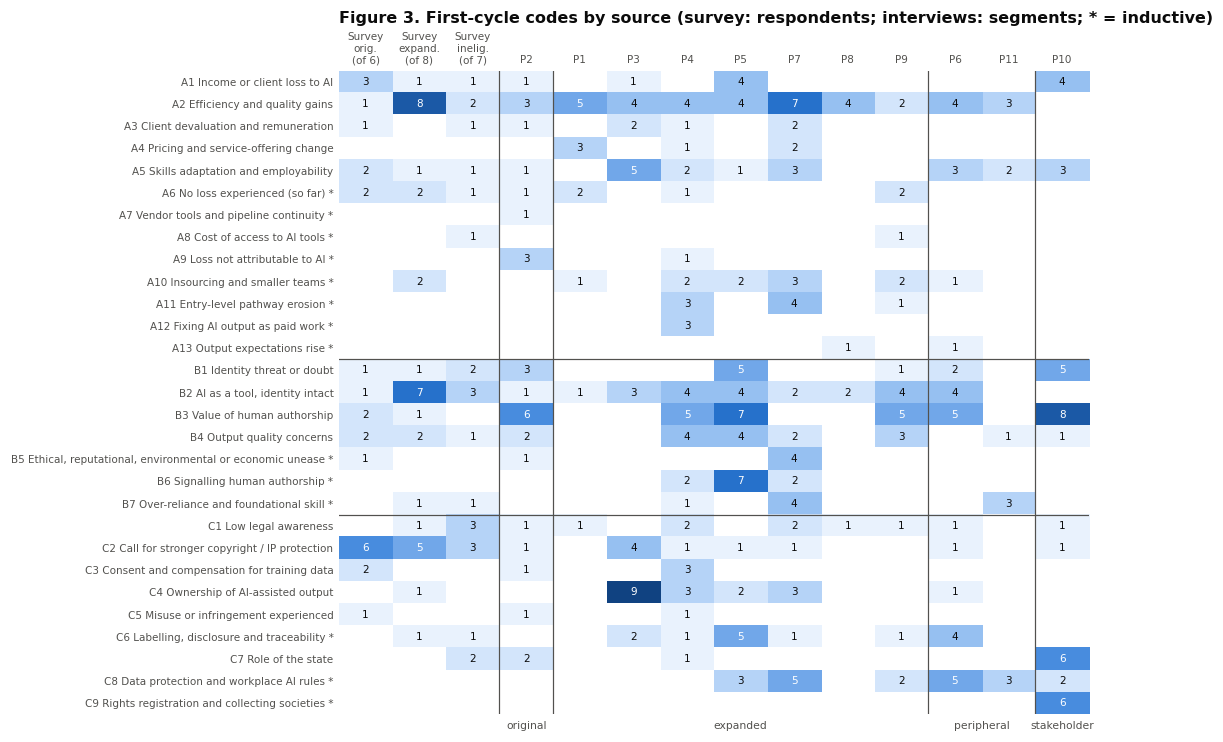

,Order,Interview,Tier,Date,Codes present,New codes,Which
0,1,P1,expanded,2026-10-12,6,1,A4
1,2,P3,expanded,2026-10-13,8,0,—
2,3,P2,original,2026-10-14,17,2,"A7, A9"
3,4,P4,expanded,2026-10-19,21,3,"A11, A12, B6"
4,5,P5,expanded,2026-10-19,13,1,C8
5,6,P6,peripheral,2026-10-20,12,1,A13
6,7,P7,expanded,2026-10-20,16,0,—
7,8,P8,expanded,2026-10-20,4,0,—
8,9,P9,expanded,2026-10-23,12,0,—
9,10,P10,stakeholder,2026-11-03,10,1,C9


Saturation rule (two consecutive interviews with no new codes): MET at P8


In [27]:
# Figure 3 — code × source matrix (sequential single hue; the table above is the exact view)
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("blues", ["#ffffff", "#cde2fb", "#86b6ef", "#2a78d6", "#104281"])
fig, ax = plt.subplots(figsize=(8.8, 7.6))
M = matrix.to_numpy(); vmax = max(M.max(), 4)
ax.imshow(M, cmap=cmap, aspect="auto", vmin=0, vmax=vmax)
for (i, j), v in np.ndenumerate(M):
    if v:
        ax.text(j, i, int(v), ha="center", va="center", fontsize=6.8, color="white" if v / vmax > 0.55 else INK)
n_core, n_adj, n_in = len(core), len(an) - len(core), int((~scr.eligible).sum())
xl = [f"Survey\norig.\n(of {n_core})", f"Survey\nexpand.\n(of {n_adj})", f"Survey\ninelig.\n(of {n_in})"] + INT_ORDER
ax.set_xticks(range(len(SRC_ORDER)), xl, fontsize=6.8); ax.xaxis.tick_top()
ax.set_yticks(range(len(matrix)), matrix.index, fontsize=6.8)
for b in [sum(c.startswith("A") for c in CODEBOOK) - 0.5, sum(c[0] in "AB" for c in CODEBOOK) - 0.5]:
    ax.axhline(b, color=INK2, linewidth=0.8)
bounds = np.cumsum([3] + [sum(TIER[p] == t for p in TIER) for t in TIER_ORDER])[:-1] - 0.5
for b in bounds:
    ax.axvline(b, color=INK2, linewidth=0.8)
for t, x0, x1 in zip(TIER_ORDER, bounds, list(bounds[1:]) + [len(SRC_ORDER) - 0.5]):
    ax.text((x0 + x1) / 2, len(matrix) - 0.2, t, ha="center", va="top", fontsize=7, color=INK2)
ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Figure 3. First-cycle codes by source (survey: respondents; interviews: segments; * = inductive)", pad=6)
save(fig, "fig3_code_matrix"); plt.show()

# Saturation monitor (ICE 1 §3.2): new codes contributed by each interview, in the order conducted
seen = set(long.loc[is_survey, "codes"]); rows = []
for r in INTERVIEWS.itertuples():
    codes_here = set(long.loc[long.unit == r.pid, "codes"]); new = sorted(codes_here - seen, key=list(CODEBOOK).index); seen |= codes_here
    rows.append([r.order, r.pid, r.tier, r.date, len(codes_here), len(new), ", ".join(new) or "—"])
saturation = pd.DataFrame(rows, columns=["Order", "Interview", "Tier", "Date", "Codes present", "New codes", "Which"])
saturation.to_csv(TAB / f"saturation_monitor_{V}.csv", index=False)
display(saturation)
run = (saturation["New codes"] == 0).astype(int)
met_at = next((saturation.Interview[i] for i in range(1, len(run)) if run[i] and run[i - 1]), None)
print("Saturation rule (two consecutive interviews with no new codes):",
      f"MET at {met_at}" if met_at else "NOT MET")

**Reasoning.** The dictionary pass produced 441 code assignments. Review changed 69 of them (44 removed, 25 added),
leaving 422 across 312 of 537 units. The removals are mostly transcription errors ("copyrighting" for *copywriting*),
negations and hypotheticals, so the pass remains a starting point, not a coding.

Three results stand out.

1. **Calls for stronger copyright and IP protection (C2)** remain the most widespread code in the survey text: 11 of 14
   eligible respondents.
2. **Insourcing (A10)** is the main new mechanism. In six interviews, and in two survey answers, buyers and employers
   describe doing with AI what they used to pay someone for: "I normally outsource most of my design work. Thanks to AI
   now, I can actually do it myself" (P7). This is the displacement that v1.1 could only infer from P1.
3. **Three new codes never appear in the original-scope interview**: signalling human authorship (B6: P4, P5, P7),
   entry-level erosion (A11: P4, P7, P9) and workplace AI rules (C8: six expanded-scope, peripheral or stakeholder
   interviews).

**Saturation.** By ICE 1's rule (two consecutive interviews with no new codes) saturation was reached at P8 (P7 and P8
added none, and only the stakeholder interview P10 added one more). Two caveats apply. The new codes were derived from
these same interviews, and the sample spans several occupations. Ahmed (2025) ties early saturation to a narrow,
homogeneous population. The result shows that this mixed sample of digital creative professionals stopped producing
new codes. It does not show saturation within any one occupation, least of all for illustrators and animators, who
are represented by a single interview.

### 9.1 Do the codes arise where the guide expects them?

Each coded interview segment is assigned to the guide section it falls in: the most recent section anchor before it.
Cross-tabulating sections against code themes checks the deductive frame. Codes should mostly appear in their matching
section. Where they appear elsewhere, the participant has connected topics that the guide treats as separate.

In [28]:
def guide_section(pid, ts):
    a = anchors[(anchors.pid == pid) & (anchors.ts <= ts)].sort_values("ts")
    return a.section.iloc[-1] if len(a) else "Opening"
iv = long[~is_survey].reset_index(drop=True)
iv["section"] = [guide_section(u, sid.split("@")[1]) for u, sid in zip(iv.unit, iv.seg_id)]
iv["theme"] = iv.codes.str[0].map({"A": "A. Work & income", "B": "B. Creative identity", "C": "C. Legal protection"})
guide_x_theme = pd.crosstab(iv.section, iv.theme, margins=True, margins_name="Total").reindex(
    [s for s in SECTIONS + ["Unscripted"] if s in set(iv.section)] + ["Total"])
guide_x_theme.to_csv(TAB / f"guide_section_by_code_theme_{V}.csv")
display(guide_x_theme)
for s, th in [("Income & displacement", "A. Work & income"), ("Creative identity", "B. Creative identity"), ("Legal protection", "C. Legal protection")]:
    sub = iv[iv.section == s]
    print(f"{s}: {int((sub.theme == th).sum())} of {len(sub)} code assignments belong to the matching theme")

theme,A. Work & income,B. Creative identity,C. Legal protection,Total
section,,,,
Opening,5,2,0,7
AI use & exposure,12,22,5,39
Income & displacement,68,22,1,91
Creative identity,24,48,2,74
Legal protection,0,3,77,80
Client perception,0,14,5,19
Closing check,1,0,0,1
Closing,7,7,3,17
Unscripted,1,0,0,1


Income & displacement: 68 of 91 code assignments belong to the matching theme
Creative identity: 48 of 74 code assignments belong to the matching theme
Legal protection: 77 of 80 code assignments belong to the matching theme


**Reasoning.** The legal questions produce legal codes almost exclusively (77 of 80 assignments), so Theme C is cleanly
bounded. Income and identity are not. A quarter of the codes in answers to *income* questions are identity codes (22 of
91), and a third of the codes in answers to *identity* questions are work-and-income codes (24 of 74). The same mix
appears when interviewees describe how they use AI. Participants do not separate "what AI does to my work" from "what AI
does to who I am", which supports T4 and means SQ1 and SQ3 should be interpreted together in the final report.

### 9.2 From codes to candidate themes

Coding breaks the data apart; analysis puts it back together. Related codes are grouped, and each group is stated as
a **claim** rather than a topic label (IIE, 2026). Each candidate theme separates its **core codes** (the ones that carry
the claim) from **related codes** (context), so a broad code such as "skills adaptation" cannot inflate a narrow claim.
Support is counted in cases (respondents, interviews) on the core codes, not in segments, because one talkative
participant should not make a theme. For the two claims that join two ideas (T2: demanded *and* not understood; T4:
threat *and* tool), the table also counts the cases that hold both. Every theme lists **disconfirming evidence**: cases
that cut against the claim, kept in view rather than dropped.

In [29]:
THEMES = {   # core = the codes that carry the claim (support is counted on these); related = context codes
    "T1": dict(claim="Displacement is real but mostly indirect: buyers and employers insource with AI and run smaller teams, so the loss is hard for the worker to see or attribute",
               core=["A10", "A9", "A1"], related=["A3"], all_core=False,
               disconfirming=[("S:R05:txt_work_income", "AI has not replaced the respondent's work or income"),
                              ("P4@12:01", "does not think he is losing clients to AI"),
                              ("P9@12:38", "does not expect AI to have an impact on her work")]),
    "T2": dict(claim="Protection is demanded but not understood: creatives want new law and stronger bodies, yet cannot say how current law applies to AI",
               core=["C2", "C1"], related=["C3", "C7", "C9"], all_core=True,
               disconfirming=[("S:R05:txt_protections", "confident existing international copyright protects their work"),
                              ("S:R15:txt_protections", "does not feel any protections are absolutely needed"),
                              ("P7@25:12", "'most of them already exist' (IP, patents)")]),
    "T3": dict(claim="Ownership of AI-assisted work is claimed through process, not law: practitioners point to prompting, paying for the tool or keeping a record (commits, date stamps) as proof",
               core=["C4"], related=["C6", "C5"], all_core=False,
               disconfirming=[("P2@27:20", "frames the issue as consent for training data, not ownership of output"),
                              ("P4@23:26", "calls ownership a grey area rather than asserting it"),
                              ("P6@29:54", "sees a loophole: nothing shows the user owns what they generate")]),
    "T4": dict(claim="Creative identity is held in tension: AI is framed as a tool while the value and future of human skill is questioned",
               core=["B1", "B2"], related=["B3", "B4", "B5"], all_core=True,
               disconfirming=[("S:R05:txt_identity", "identity rests on judgement and meaning; AI 'doesn't threaten' it"),
                              ("P1@15:02", "AI 'made me realise how good I am at my work'"),
                              ("P4@19:44", "has never seen anyone emotionally hurt by AI")]),
    "T5": dict(claim="Human-made work now has to be signalled: in a market flooded with AI output, being seen as human-made becomes part of the work",
               core=["B6"], related=["B3", "B4", "C6"], all_core=False,
               disconfirming=[("P7@27:40", "doubts that audiences can tell AI and human work apart at all"),
                              ("P10@33:03", "audiences may come to accept AI work over time")]),
    "T6": dict(claim="The entry route is narrowing: AI removes the junior work through which skills were learnt, and leaning on it erodes foundational skill",
               core=["A11", "B7"], related=["A5"], all_core=False,
               disconfirming=[("P5@13:39", "AI helps newcomers learn and join the team"),
                              ("P7@17:47", "AI let a self-taught developer build the portfolio that got him clients")]),
    "T7": dict(claim="Rules for AI at work come from employers and data-protection law, not copyright: approved tools, POPIA and in-house policies govern daily use",
               core=["C8"], related=[], all_core=False,
               disconfirming=[("P10@28:41", "the department has issued no AI guidance yet"),
                              ("P4@32:14", "does not disclose AI use to clients unless asked")]),
}
all_ids = set(corpus.seg_id)
case_codes = long.groupby(["source", "unit"]).codes.agg(set)
rows = []
for t, spec in THEMES.items():
    assert all(sid in all_ids for sid, _ in spec["disconfirming"]), t
    m = long[long.codes.isin(spec["core"])]
    sv = m[(m.source == "Survey") & (m.eligible == True)]
    ints = m[m.source == "Interview"]
    by_tier = " · ".join(f"{t_}: {', '.join(sorted(ints[ints.tier == t_].unit.unique(), key=lambda p: int(p[1:])))}"
                         for t_ in TIER_ORDER if (ints.tier == t_).any())
    both = "—"
    if spec["all_core"]:
        has_all = lambda src, units: sum(set(spec["core"]) <= case_codes.get((src, u), set()) for u in units)
        both = (f"survey {has_all('Survey', an.resp_id)}/{len(an)}; "
                f"interviews {has_all('Interview', INTERVIEWS.pid)}/{len(INTERVIEWS)}")
    seg_all = long[(long.source == "Interview") & long.codes.isin(spec["core"] + spec["related"])].seg_id.nunique()
    rows.append([t, spec["claim"], ", ".join(spec["core"]), ", ".join(spec["related"]) or "—",
                 f"{sv.unit.nunique()}/{len(an)} (original {sv[sv.tier == 'original'].unit.nunique()}/{len(core)})",
                 f"{ints.unit.nunique()}/{len(INTERVIEWS)}", by_tier, both, seg_all,
                 "; ".join(f"{sid}: {why}" for sid, why in spec["disconfirming"])])
candidate_themes = pd.DataFrame(rows, columns=["Theme", "Candidate claim", "Core codes", "Related codes",
                                               "Eligible survey respondents (core codes)", "Interviews (core codes)",
                                               "Interviews by tier (core codes)", "Cases holding every core code",
                                               "Interview segments (core + related)", "Disconfirming evidence"])
candidate_themes.to_csv(TAB / f"candidate_themes_{V}.csv", index=False)
display(candidate_themes)

,Theme,Candidate claim,Core codes,Related codes,Eligible survey respondents (core codes),Interviews (core codes),Interviews by tier (core codes),Cases holding every core code,Interview segments (core + related),Disconfirming evidence
0,T1,"Displacement is real but mostly indirect: buyers and employers insource with AI and run smaller teams, so ...","A10, A9, A1",A3,6/14 (original 3/6),9/11,"original: P2 · expanded: P1, P3, P4, P5, P7, P9 · peripheral: P6 · stakeholder: P10",—,30,S:R05:txt_work_income: AI has not replaced the respondent's work or income; P4@12:01: does not think he is...
1,T2,"Protection is demanded but not understood: creatives want new law and stronger bodies, yet cannot say how ...","C2, C1","C3, C7, C9",12/14 (original 6/6),10/11,"original: P2 · expanded: P1, P3, P4, P5, P7, P8, P9 · peripheral: P6 · stakeholder: P10",survey 0/14; interviews 5/11,33,S:R05:txt_protections: confident existing international copyright protects their work; S:R15:txt_protectio...
2,T3,"Ownership of AI-assisted work is claimed through process, not law: practitioners point to prompting, payin...",C4,"C6, C5",1/14 (original 0/6),5/11,"expanded: P3, P4, P5, P7 · peripheral: P6",—,32,"P2@27:20: frames the issue as consent for training data, not ownership of output; P4@23:26: calls ownershi..."
3,T4,Creative identity is held in tension: AI is framed as a tool while the value and future of human skill is ...,"B1, B2","B3, B4, B5",9/14 (original 2/6),10/11,"original: P2 · expanded: P1, P3, P4, P5, P7, P8, P9 · peripheral: P6 · stakeholder: P10",survey 1/14; interviews 4/11,76,S:R05:txt_identity: identity rests on judgement and meaning; AI 'doesn't threaten' it; P1@15:02: AI 'made ...
4,T5,"Human-made work now has to be signalled: in a market flooded with AI output, being seen as human-made beco...",B6,"B3, B4, C6",0/14 (original 0/6),3/11,"expanded: P4, P5, P7",—,66,P7@27:40: doubts that audiences can tell AI and human work apart at all; P10@33:03: audiences may come to ...
5,T6,"The entry route is narrowing: AI removes the junior work through which skills were learnt, and leaning on ...","A11, B7",A5,1/14 (original 0/6),4/11,"expanded: P4, P7, P9 · peripheral: P11",—,33,P5@13:39: AI helps newcomers learn and join the team; P7@17:47: AI let a self-taught developer build the p...
6,T7,"Rules for AI at work come from employers and data-protection law, not copyright: approved tools, POPIA and...",C8,—,0/14 (original 0/6),6/11,"expanded: P5, P7, P9 · peripheral: P6, P11 · stakeholder: P10",—,20,P10@28:41: the department has issued no AI guidance yet; P4@32:14: does not disclose AI use to clients unl...


**Reasoning.** Seven candidate themes are stated as claims, with support counted on their core codes only. They fall
into three groups by strength.

- **Broad and cross-strand: T2 and T4.** T2 (protection demanded but not understood) is carried by 12 of 14 eligible
  respondents (all six in the original scope) and 10 of 11 interviews. The conjunction rests mainly on the structured
  items (8 of 14 support new law without understanding copyright) and on five interviews that hold both codes. T4
  (identity in tension) appears in 10 interviews. Four of them, including P2, move between threat and tool within the
  same interview, and six survey respondents agree with both Q5.1 and Q5.7.
- **Supported, and now with a mechanism: T1.** Nine interviews carry loss, non-attributable loss or insourcing. The
  original-scope artist (P2) describes loss that cannot be attributed. Six interviewees, mostly buyers and employers,
  describe insourcing. Together they explain why only 4 of 14 survey respondents attribute loss to AI.
- **Expanded-scope themes: T3, T5, T6, T7.** Each rests on four to six interviews (T5 on three), all from the expanded
  scope, the peripheral roles and (for T7) the stakeholder. T3 (ownership claimed through process) comes mostly from developers and designers,
  plus P3, and P2's framing (consent, not ownership) cuts against it. Since the scope expansion these are legitimate
  findings about digital creative professionals in design, development and social media. The original-scope artist
  supports none of them, so the report should not generalise them to illustrators and animators. Documents are the
  best way to test T3 and T7.

As the lecture guidance notes, frequency alone does not make a theme important. Here frequency mostly reflects where
the interviews came from: seven of the eleven are from the expanded scope.

## 10. Extended VADER sentiment (SQ3 — descriptive only)

VADER (Hutto & Gilbert, 2014) is run in two forms: the **base lexicon**, and the base lexicon plus a **domain
extension (v1.0)** following Barik & Misra (2024). As ICE 1 §3.6 requires, the extension was fixed **before any score
was computed** (15 Oct 2026), and it is applied unchanged to the new data: adding terms after seeing the new
transcripts would break the pre-fixed rule. Thresholds are the VADER standard (compound ≥ +0.05 positive, ≤ −0.05
negative). Sentiment is reported descriptively and is not used as a predictor.

Segments whose class changed after the extension: 5 of 537


,Question / source,Units,People,Mean compound (base),Mean compound (extended),Positive,Neutral,Negative
0,Q6.1 Work & income,20,20,0.14,0.19,9,5,6
1,Q6.2 Identity & purpose,20,20,0.27,0.28,13,4,3
2,Q6.3 Protections needed,20,20,0.16,0.14,8,8,4
3,Q6.4 Anything else,10,10,0.32,0.32,7,0,3
4,Interview: original (P2),32,1,0.52,0.52,25,4,3
5,Interview: expanded (7),261,7,0.47,0.46,210,37,14
6,Interview: peripheral (2),108,2,0.39,0.40,82,18,8
7,Interview: stakeholder (P10),66,1,0.61,0.60,60,4,2


saved → outputs/figures/fig4_sentiment.png


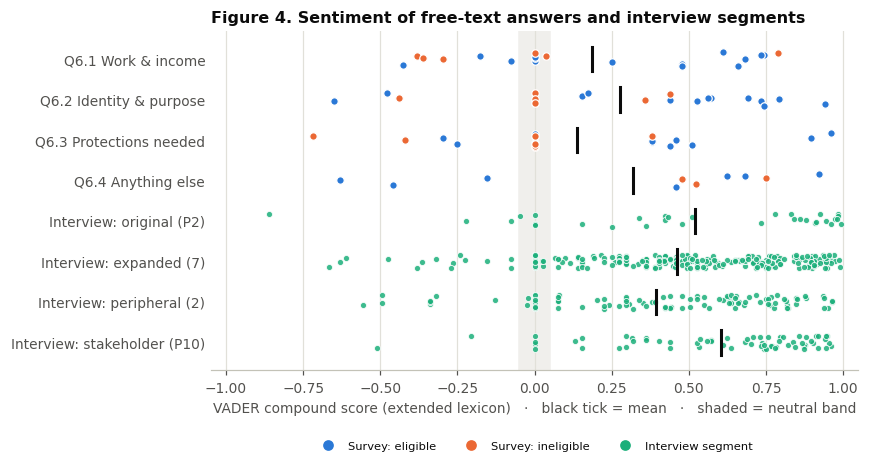

Validation subset exported for blind rubric coding: 161 units → tables/sentiment_validation_subset_v2.csv


In [30]:
EXTENSION_LEXICON_V1 = {   # frozen 15 Oct 2026, before scoring — term: (valence, justification)
    "slop":         (-1.5, "pejorative term for mass-produced, low-quality AI output"),
    "plagiarism":   (-2.0, "unauthorised copying; aligned with base 'stolen' (-2.2)"),
    "plagiarised":  (-2.0, "as above"),
    "theft":        (-2.2, "aligned with base 'stolen' (-2.2)"),
    "redundant":    (-1.5, "job-loss sense in labour-market talk"),
    "redundancy":   (-1.5, "as above"),
    "displaced":    (-1.5, "worker displacement by automation"),
    "displacement": (-1.5, "as above"),
    "replaced":     (-1.5, "artist replaced by AI; VADER's negation rule handles 'not replaced'"),
    "replace":      (-1.0, "weaker base form of the above"),
    "devalued":     (-1.8, "loss of perceived worth of creative labour"),
    "undercut":     (-1.5, "price competition from AI alternatives"),
    "scraped":      (-1.0, "training data collected without consent"),
    "faster":       (+1.0, "turnaround gain, positive from the practitioner's own standpoint"),
}
base = SentimentIntensityAnalyzer()
ext = SentimentIntensityAnalyzer()
already = [w for w in EXTENSION_LEXICON_V1 if w in base.lexicon]
assert not already, f"Extension must only add missing terms: {already}"
ext.lexicon.update({w: v for w, (v, _) in EXTENSION_LEXICON_V1.items()})
pd.DataFrame([(w, v, j) for w, (v, j) in EXTENSION_LEXICON_V1.items()],
             columns=["term", "valence", "justification"]).to_csv(TAB / f"vader_extension_lexicon_{V}.csv", index=False)

label = lambda c: "positive" if c >= 0.05 else "negative" if c <= -0.05 else "neutral"
corpus["vader_base"] = corpus.text.map(lambda t: base.polarity_scores(t)["compound"])
corpus["vader_ext"]  = corpus.text.map(lambda t: ext.polarity_scores(t)["compound"])
corpus["sentiment"]  = corpus.vader_ext.map(label)
changed = corpus[corpus.vader_base.map(label) != corpus.sentiment]
print(f"Segments whose class changed after the extension: {len(changed)} of {len(corpus)}")

TIER_LABEL = {"original": "Interview: original (P2)", "expanded": "Interview: expanded (7)", "peripheral": "Interview: peripheral (2)",
              "stakeholder": "Interview: stakeholder (P10)"}
corpus["group"] = np.where(corpus.source == "Survey", corpus.question, corpus.tier.map(TIER_LABEL))
order = list(TEXT_COLS.values()) + list(TIER_LABEL.values())
rows = []
for g in order:
    d = corpus[corpus.group == g]; vc = d.sentiment.value_counts()
    rows.append([g, len(d), d.unit.nunique(), round(d.vader_base.mean(), 2), round(d.vader_ext.mean(), 2),
                 vc.get("positive", 0), vc.get("neutral", 0), vc.get("negative", 0)])
sentiment_summary = pd.DataFrame(rows, columns=["Question / source", "Units", "People", "Mean compound (base)",
                                                "Mean compound (extended)", "Positive", "Neutral", "Negative"])
sentiment_summary.to_csv(TAB / f"sentiment_summary_{V}.csv", index=False)
display(sentiment_summary)
corpus[["seg_id", "src", "question", "vader_base", "vader_ext", "sentiment", "text"]].to_csv(TAB / f"sentiment_scores_{V}.csv", index=False)

# Figure 4 — every scored unit as a dot; neutral band shaded
fig, ax = plt.subplots(figsize=(7.6, 4.0))
ax.axvspan(-0.05, 0.05, color="#f0efec", zorder=0)
for i, g in enumerate(order):
    d = corpus[corpus.group == g]
    jitter = rng.uniform(-0.17, 0.17, len(d))
    if g.startswith("Q"):
        for el, col in [(True, C_ELIG), (False, C_ALL)]:
            m = (d.eligible == el).to_numpy()
            ax.scatter(d.vader_ext[m], np.full(m.sum(), i) + jitter[m], s=24, color=col, edgecolor="white", linewidth=0.8, zorder=3)
    else:
        ax.scatter(d.vader_ext, np.full(len(d), i) + jitter, s=16, color=C_INT, edgecolor="white", linewidth=0.6, alpha=0.85, zorder=3)
    ax.plot([d.vader_ext.mean()] * 2, [i - 0.3, i + 0.3], color=INK, linewidth=2, zorder=4)
ax.set_yticks(range(len(order)), order); ax.invert_yaxis(); ax.set_xlim(-1.05, 1.05)
ax.set_xlabel("VADER compound score (extended lexicon)   ·   black tick = mean   ·   shaded = neutral band")
ax.xaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True); ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
handles = [mpl.lines.Line2D([], [], marker="o", ls="", color=c, markersize=6, label=l)
           for c, l in [(C_ELIG, "Survey: eligible"), (C_ALL, "Survey: ineligible"), (C_INT, "Interview segment")]]
ax.legend(handles=handles, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=7.5)
ax.set_title("Figure 4. Sentiment of free-text answers and interview segments")
save(fig, "fig4_sentiment"); plt.show()

# Validation subset for rubric coding (ICE 1 §3.6): 30% random sample, seeded, blank columns for the researcher
val = corpus.sample(frac=0.30, random_state=SEED)[["seg_id", "question", "text"]].copy()
OBJECT = {"Q6.1 Work & income": "effect of AI on the respondent's own work and income",
          "Q6.2 Identity & purpose": "effect of AI on the respondent's creative identity",
          "Q6.3 Protections needed": "adequacy of current protection (needs implying inadequacy = negative)",
          "Q6.4 Anything else": "overall stance towards generative AI", "Interview": "the topic of the question being answered"}
val["sentiment_object"] = val.question.map(OBJECT)
for c in ["code_round1 (-1/0/+1)", "date_round1", "code_round2 (≥ 7 days later)", "date_round2"]:
    val[c] = ""
val.to_csv(TAB / f"sentiment_validation_subset_{V}.csv", index=False)
print(f"Validation subset exported for blind rubric coding: {len(val)} units → tables/sentiment_validation_subset_{V}.csv")

**Reasoning.** The domain extension changed the class of only 5 of 537 units, so the results do not depend on it. The
lexicon was applied unchanged to the new data, as the pre-fixing rule requires.

Survey free text is mildly positive on average (means 0.14 to 0.32). Q6.1 (work and income) remains the most negative
question, with 6 of 20 answers negative. Interview segments score much higher (0.40 to 0.60), and the stakeholder
interview is the most positive. That reflects conversational speech and politeness as much as attitude to AI.

The object-of-sentiment problem from v1.1 persists. Eight of 20 answers about *protections needed* (Q6.3) score as
positive because they contain words such as "protect" and "fair", although asking for protection implies current
protection is inadequate. The validation subset has been regenerated for the full corpus (161 units). If round-1
coding of the v1.1 subset has already started, keep it and code only the units that are new. Sentiment stays
exploratory until κ ≥ 0.60 is reached.

## 11. Integration preview: the triangulation matrix

This is the interface point of the explanatory sequential design. Each survey finding is paired with what the
interviews say about it, with the interview evidence split by tier so it is clear whose experience it is. The
documentary column stays empty until the document register is built.

In [31]:
def k_of(d, f): return f"{int(f(d).sum())}/{len(d)}"
sp = lambda code: spread.loc[[i for i in spread.index if i.startswith(code + " ")][0]]
def ints(code):
    s = sp(code)
    by = ", ".join(f"{t} {s[c]}" for t in TIER_ORDER for c in s.index if c.startswith(f"Interviews: {t} "))
    return f"{s[INT_COL]}/{len(INTERVIEWS)} interviews ({by})"
v2_role = df.set_index("resp_id").loc[v2e.resp_id, "role_change"].dropna()
v2_pol = df.set_index("resp_id").loc[v2e.resp_id, "employer_policy"]
tri = pd.DataFrame([
    ["SQ1: A minority report AI-attributed loss",
     f"Q3.4 Yes: {k_of(an, lambda d: d.ai_loss == 1)} eligible (original {k_of(core, lambda d: d.ai_loss == 1)}); "
     f"any loss incl. Q3.3: {k_of(an, lambda d: d.any_ai_loss == 1)}",
     f"A1 loss: {ints('A1')}; A10 insourcing: {ints('A10')}; A9 not attributable: {ints('A9')}",
     "Explains the low count: substitution happens on the buyer's side and is rarely visible to the worker"],
    ["SQ2/H3: Legal knowledge is low",
     f"Q4.2 understand, % agree: {(an.leg_understand >= 4).mean():.0%}; Q4.5 know steps: {(an.leg_know_steps >= 4).mean():.0%}",
     f"C1 low awareness: {ints('C1')}",
     "Convergence across structured items, free text and interviews"],
    ["SQ3: Strong demand for protection",
     f"Q4.4 support new law, % agree: {(an.leg_support_new >= 4).mean():.0%}; Q4.6 bodies should do more: "
     f"{(an.leg_industry_bodies >= 4).mean():.0%}; Q4.3 law adequate: {(an.leg_adequate >= 4).mean():.0%}; "
     f"support new law but do not understand copyright (Q4.4 ≥ 4, Q4.2 < 4): {k_of(an, lambda d: (d.leg_support_new >= 4) & (d.leg_understand < 4))}",
     f"C2 protection: {sp('C2')[SURV_COL]} eligible resp., {ints('C2')}; C9 collecting societies: stakeholder only",
     "Convergence; the stakeholder shows an existing rights infrastructure (music) that visual creatives lack"],
    ["SQ3: Identity: threatened and tool-positive at once",
     f"Q5.1 threatened, % agree: {(an.id_threat >= 4).mean():.0%}; Q5.7 tool not replacement: {(an.id_tool_not_replace >= 4).mean():.0%}; "
     f"agree with both: {k_of(an, lambda d: (d.id_threat >= 4) & (d.id_tool_not_replace >= 4))}",
     f"B1 threat: {ints('B1')}; B2 tool: {ints('B2')}",
     "Ambivalence confirmed; several interviewees move from threat to tool within one answer"],
    ["SQ3: Clients still value human-made work",
     f"Q5.5 clients value human-made work, % agree: {(an.id_client_value_human >= 4).mean():.0%} (original {(core.id_client_value_human >= 4).mean():.0%})",
     f"B3 human authorship: {ints('B3')}; B6 signalling human work: {ints('B6')}; client perception covered in {len(cp)}/11",
     "Convergence with a condition: value is recognised only when the work is visibly human"],
    ["New: The entry route is narrowing",
     f"Q3.8 'fewer junior or entry-level roles' (v2 only): {int(v2_role.str.contains('junior').sum())} of {len(v2_role)} eligible v2",
     f"A11 junior roles: {ints('A11')}; B7 foundational skill: {ints('B7')}",
     "Interview-led; the survey item is v2-only and thin, so this rests on the interviews"],
    ["New: Workplace rules govern AI use",
     f"Q2.8 written employer/client AI policy (v2 only): Yes {int((v2_pol == 'Yes').sum())} of {v2_pol.notna().sum()} eligible v2",
     f"C8 data protection and workplace rules: {ints('C8')}",
     "Interview-led, from expanded-scope and peripheral roles; no original-scope evidence"],
], columns=["Finding", "Survey evidence (eligible)", "Interview evidence (by tier)", "Assessment"])
tri["Documentary evidence"] = "Pending (register not started)"
tri.to_csv(TAB / f"triangulation_{V}.csv", index=False)
display(tri)

,Finding,Survey evidence (eligible),Interview evidence (by tier),Assessment,Documentary evidence
0,SQ1: A minority report AI-attributed loss,Q3.4 Yes: 4/14 eligible (original 2/6); any loss incl. Q3.3: 5/14,"A1 loss: 4/11 interviews (original 1, expanded 2, peripheral 0, stakeholder 1); A10 insourcing: 6/11 inter...",Explains the low count: substitution happens on the buyer's side and is rarely visible to the worker,Pending (register not started)
1,SQ2/H3: Legal knowledge is low,"Q4.2 understand, % agree: 36%; Q4.5 know steps: 29%","C1 low awareness: 8/11 interviews (original 1, expanded 5, peripheral 1, stakeholder 1)","Convergence across structured items, free text and interviews",Pending (register not started)
2,SQ3: Strong demand for protection,"Q4.4 support new law, % agree: 86%; Q4.6 bodies should do more: 79%; Q4.3 law adequate: 29%; support new l...","C2 protection: 11 eligible resp., 7/11 interviews (original 1, expanded 4, peripheral 1, stakeholder 1); C...",Convergence; the stakeholder shows an existing rights infrastructure (music) that visual creatives lack,Pending (register not started)
3,SQ3: Identity: threatened and tool-positive at once,"Q5.1 threatened, % agree: 50%; Q5.7 tool not replacement: 86%; agree with both: 6/14","B1 threat: 5/11 interviews (original 1, expanded 2, peripheral 1, stakeholder 1); B2 tool: 9/11 interviews...",Ambivalence confirmed; several interviewees move from threat to tool within one answer,Pending (register not started)
4,SQ3: Clients still value human-made work,"Q5.5 clients value human-made work, % agree: 57% (original 67%)","B3 human authorship: 6/11 interviews (original 1, expanded 3, peripheral 1, stakeholder 1); B6 signalling ...",Convergence with a condition: value is recognised only when the work is visibly human,Pending (register not started)
5,New: The entry route is narrowing,Q3.8 'fewer junior or entry-level roles' (v2 only): 1 of 7 eligible v2,"A11 junior roles: 3/11 interviews (original 0, expanded 3, peripheral 0, stakeholder 0); B7 foundational s...","Interview-led; the survey item is v2-only and thin, so this rests on the interviews",Pending (register not started)
6,New: Workplace rules govern AI use,Q2.8 written employer/client AI policy (v2 only): Yes 3 of 7 eligible v2,"C8 data protection and workplace rules: 6/11 interviews (original 0, expanded 3, peripheral 2, stakeholder 1)","Interview-led, from expanded-scope and peripheral roles; no original-scope evidence",Pending (register not started)


**Reasoning.** At the close of fieldwork the strands agree on legal protection: demand is high and working knowledge is
low, in the structured items, the free text and the interviews. On income they diverge, and usefully. The survey shows
few people attributing loss to AI. The interviews explain why: displacement happens on the buyer's side through
insourcing and smaller teams, and the creative who loses a bid rarely learns the reason.

Three cautions belong in ICE 3 and ICE 4.
1. The interview explanations come mostly from the expanded scope, and several interviewees speak as buyers or
   employers. That is a strength for explaining the mechanism, but only P2 speaks from the original population.
2. The two new rows (entry-level erosion, workplace rules) are interview-led, and the survey items that could
   corroborate them exist only in v2.
3. The documentary column is empty. The document strand is the remaining way to test T2, T3 and T7 against the actual
   state of South African law.

## 12. Save the versioned analysis dataset and session summary

In [32]:
drop = ["timestamp", "purposes_other_text"] + [c for c in enc.columns if c.startswith("txt_")]
keep = [c for c in enc.columns if c not in drop]
clean = enc[keep].merge(scr[["resp_id", "eligible", "flag_straightline", "n_flags", "in_analysis"]], on="resp_id")
clean.to_csv(TAB / f"clean_{V}.csv", index=False)
survey_text.to_csv(TAB / f"text_corpus_survey_{V}.csv", index=False)

print("=" * 76); print(" ICE 2 ANALYSIS v2.1 — SUMMARY (final fieldwork data)"); print("=" * 76)
print(f" Survey: {len(df)} submissions (v1 {int(v1.sum())}, v2 {int((~v1).sum())}) · eligible {len(an)} (original scope {len(core)}, expanded {len(adj)}) "
      f"(ICE 1 target 80, floor 50)")
print(f" Primary outcome (Q3.4): eligible {an.ai_loss.mean():.0%} [{wilson(int(an.ai_loss.sum()), len(an))[0]:.0%}–"
      f"{wilson(int(an.ai_loss.sum()), len(an))[1]:.0%}], original scope {core.ai_loss.mean():.0%}, all {alln.ai_loss.mean():.0%} (planning value 55%)")
print(f" Modelling: abandoned under the ICE 1 contingency (n < 50 at close)")
print(f" Interviews: {len(INTERVIEWS)} · tiers {INTERVIEWS.tier.value_counts().reindex(TIER_ORDER).to_dict()} · "
      f"segments coded {len(interview_corpus)} · saturation {'met at ' + met_at if met_at else 'not met'}")
print(f" Codebook v0.3: {len(CODEBOOK)} codes ({sum(v['origin'] == 'inductive' for v in CODEBOOK.values())} inductive) · "
      f"{len(override_log)} logged review decisions · {len(THEMES)} candidate themes")
print(f" Outputs written: {len(list(FIG.glob('*.png')))} figures, {len(list(TAB.glob('*_' + V + '.csv')))} tables")

 ICE 2 ANALYSIS v2.1 — SUMMARY (final fieldwork data)
 Survey: 21 submissions (v1 13, v2 8) · eligible 14 (original scope 6, expanded 8) (ICE 1 target 80, floor 50)
 Primary outcome (Q3.4): eligible 29% [12%–55%], original scope 33%, all 29% (planning value 55%)
 Modelling: abandoned under the ICE 1 contingency (n < 50 at close)
 Interviews: 11 · tiers {'original': 1, 'expanded': 7, 'peripheral': 2, 'stakeholder': 1} · segments coded 467 · saturation met at P8
 Codebook v0.3: 29 codes (14 inductive) · 69 logged review decisions · 7 candidate themes
 Outputs written: 4 figures, 33 tables


## 13. Where the analysis stands

| Area | Status at close of fieldwork | Next action (ICE 3 / ICE 4) |
|---|---|---|
| Survey sample | 21 submitted, 14 eligible: **6 original scope** (all v1), 8 expanded scope; target 80, floor 50 | Report the shortfall and the ICE 1 contingency prominently; present the two scope groups side by side |
| Scope and instrument | Scope expanded to digital creative professionals (researcher's decision, supervisor informed); two form versions; integrity check passes | State the expansion, its date and reason in ICE 3; check that the title, aims and sub-questions match the wider population |
| Primary outcome | Q3.4 29% (12%–55%); losses concentrated in the original scope; Q3.4 contradicts other items for 2 respondents | Report Q3.4 with the broad outcome; treat both as descriptive |
| Reliability | Identity scale α 0.86; legal knowledge α 0.77 (Q4.1 weakest) | Report with intervals; keep H3a and H3b separate |
| Bivariate / modelling | No test supports H1–H3; H1 direction reversed; modelling **abandoned** (ICE 1 contingency) | Reframe SQ2 as association; discuss H1 reversal using T1 |
| Interviews | 11 conducted (1 original, 7 expanded, 2 peripheral, 1 stakeholder); saturation rule met at P8 for the mixed sample; client perception never covered with the original-scope artist | Report scope tiers in the methods; verify transcripts against the audio; confirm P11's date |
| Thematic coding | Codebook v0.3 (29 codes, 8 new); 69 logged review decisions; 7 candidate themes (T1, T2, T4 broad; T3, T5–T7 expanded-scope) | Second-cycle coding; check theme claims against the audio; test T2, T3 and T7 with documents |
| Sentiment | Extended VADER run; validation subset regenerated (161 units) | Blind rubric coding in two rounds ≥ 7 days apart; report κ |
| Documents | Not started | Build the register (8–12 documents, ICE 1 §3.3) and code it with codebook v0.3 |
| Data protection | Contact column still in the export (dropped before analysis); transcripts de-identified | Delete Q7.2 from any shared copy; keep originals and the pseudonym key on OneDrive only; never commit them to Git |

## Reference List

Ahmed, S. K., 2025. *Sample size for saturation in qualitative research: Debates, definitions, and strategies.* [Online] Available at: https://www.sciencedirect.com/science/article/pii/S2949916X24001245 [Accessed 4 May 2026].

Ahmed, S. K. et al., 2025. *Using thematic analysis in qualitative research.* [Online] Available at: https://www.sciencedirect.com/science/article/pii/S2949916X25000222 [Accessed 5 May 2026].

Andrade, C., 2021. *The Inconvenient Truth About Convenience and Purposive Samples.* [Online] Available at: https://journals.sagepub.com/doi/10.1177/0253717620977000 [Accessed 5 May 2026].

Barik, K. & Misra, S., 2024. *Analysis of customer reviews with an improved VADER lexicon classifier.* [Online] Available at: https://link.springer.com/article/10.1186/s40537-023-00861-x [Accessed 13 September 2026].

Hutto, C. J. & Gilbert, E., 2014. *VADER: A Parsimonious Rule-Based Model for Sentiment Analysis of Social Media Text.* [Online] Available at: https://ojs.aaai.org/index.php/ICWSM/article/view/14550 [Accessed 13 September 2026].

Mbonambi, A. L., 2026. *ICE Task 1 – Methodology Refinement & Practical Implementation Plan (V2).* [Unpublished coursework]. RPDA8412: Research Project. The Independent Institute of Education.

Riley, R., 2020. *Research Methods & Reporting - Calculating the sample size required for developing a clinical prediction model.* [Online] Available at: https://www.bmj.com/content/368/bmj.m441 [Accessed 13 September 2026].

South African Government, 2013. *Protection of Personal Information Act 4 of 2013.* [Online] Available at: https://www.gov.za/documents/protection-personal-information-act [Accessed 22 May 2026].

The Independent Institute of Education (IIE), 2026. *Qualitative Data Analysis in Action.* [PowerPoint presentation, 9 September 2026]. RPDA8412: Research Project. IIE Emeris Online. Unpublished.

Ward, M. & Meade, A. W., 2023. *Dealing with Careless Responding in Survey Data: Prevention, Identification, and Recommended Best Practices.* [Online] Available at: https://www.annualreviews.org/content/journals/10.1146/annurev-psych-040422-045007 [Accessed 13 September 2026].

*The screening, sample-size, coding and sentiment rules applied in this notebook were fixed in advance in Mbonambi (2026).*